In [1]:
!pip install -q lightgbm joblib pandas numpy scikit-learn

In [2]:
from google.colab import files

uploaded = files.upload()

ModuleNotFoundError: No module named 'google.colab'

In [3]:
import os

print(os.listdir())

['.anaconda', '.antigravity', '.antigravity-ide', '.cache', '.codex', '.conda', '.config', '.continuum', '.copilot', '.cursor', '.eclipse', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.m2', '.matplotlib', '.node_repl_history', '.p2', '.securecoder', '.ssh', '.streamlit', '.th-client', '.viminfo', '.virtual_documents', '.vscode', '.vscode-shared', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Codeforces User–Problem Interaction Dataset for Pe.zip', 'codeforces_dataset', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'Favorites', 'forage-midas', 'git', 'House_Price_Prediction', 'HTML', 'Installation', 'Links', 'loan_approval_data (1).csv', 'Local Settings', 'Music', 'My Documents', 'myproject', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf.cnpf', 'NTUSER.DAT{2ad838

In [4]:
import zipfile
import os

zip_path = "Codeforces User–Problem Interaction Dataset for Pe.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("codeforces_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [5]:
for root, folders, files_list in os.walk("codeforces_dataset"):
    for file in files_list:
        print(os.path.join(root, file))

codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\fetch_data.py
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\fetch_problems.py
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\preprocess.py
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\problems.csv
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\processed_data.csv
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\team_submissions.csv
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\team_user_features.csv
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\team_user_tag_weakness.csv
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\user_features.csv
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\user_features.py
codeforces_dataset\Codeforces User–Problem Interaction Dataset for Pe\user_rating_weakness.csv
codeforces_dataset\Co

In [6]:
import pandas as pd

base = "codeforces_dataset/Codeforces User–Problem Interaction Dataset for Pe"

interactions = pd.read_csv(f"{base}/processed_data.csv")
problems = pd.read_csv(f"{base}/problems.csv")
users = pd.read_csv(f"{base}/user_features.csv")

print("Interactions shape:", interactions.shape)
print("Problems shape:", problems.shape)
print("Users shape:", users.shape)

Interactions shape: (921797, 6)
Problems shape: (10864, 3)
Users shape: (995, 9)


In [7]:
print("INTERACTIONS COLUMNS:")
print(interactions.columns.tolist())

print("\nPROBLEMS COLUMNS:")
print(problems.columns.tolist())

print("\nUSER FEATURES COLUMNS:")
print(users.columns.tolist())

INTERACTIONS COLUMNS:
['user', 'problem_id', 'solved', 'attempts', 'rating', 'tags']

PROBLEMS COLUMNS:
['problem_id', 'rating', 'tags']

USER FEATURES COLUMNS:
['user', 'solved', 'attempts', 'solve_rate', 'avg_attempts', 'avg_problem_rating', 'max_problem_rating', 'rating', 'max_rating']


In [8]:
tag_weakness = pd.read_csv(
    f"{base}/user_tag_weakness.csv"
)

rating_weakness = pd.read_csv(
    f"{base}/user_rating_weakness.csv"
)

print("USER TAG WEAKNESS")
print("Shape:", tag_weakness.shape)
print("Columns:", tag_weakness.columns.tolist())

print("\nUSER RATING WEAKNESS")
print("Shape:", rating_weakness.shape)
print("Columns:", rating_weakness.columns.tolist())

USER TAG WEAKNESS
Shape: (34138, 10)
Columns: ['user', 'tag', 'attempts', 'solved', 'solve_rate', 'avg_rating', 'mastery', 'skill_score', 'weakness_score', 'is_weak']

USER RATING WEAKNESS
Shape: (12658, 12)
Columns: ['user', 'rating_bucket', 'attempts', 'solved', 'solve_rate', 'expected_rate', 'performance_ratio', 'avg_rating', 'mastery', 'skill_score', 'weakness_score', 'is_weak']


In [9]:
display(tag_weakness.head())
display(rating_weakness.head())

,user,tag,attempts,solved,solve_rate,avg_rating,mastery,skill_score,weakness_score,is_weak
0,-1e11,ternary search,49,15,0.3061,1806.67,2.7726,1.5334,0.7195,1
1,-1e11,interactive,197,65,0.3299,1992.31,4.1897,2.7541,0.6828,1
2,-1e11,chinese remainder theorem,17,6,0.3529,1800.00,1.9459,1.2362,0.6349,0
3,-1e11,*special,30,11,0.3667,1536.36,2.4849,1.3998,0.6241,1
4,-1e11,fft,14,5,0.3571,2420.00,1.7918,1.5486,0.6236,0


,user,rating_bucket,attempts,solved,solve_rate,expected_rate,performance_ratio,avg_rating,mastery,skill_score,weakness_score,is_weak
0,-1e11,1400,1210,792,0.6545,0.70,0.9351,1449.37,6.6758,6.3332,0.0420,0
1,-1e11,1200,832,622,0.7476,0.78,0.9585,1253.22,6.4345,6.0285,0.0293,0
2,-1e11,1000,644,530,0.8230,0.85,0.9682,1054.91,6.2748,5.4475,0.0240,0
3,-1e11,800,1129,989,0.8760,0.90,0.9733,820.22,6.8977,4.9561,0.0214,0
4,-1e11,2200,1600,529,0.3306,0.35,0.9446,2238.19,6.2729,4.6419,0.0197,0


In [10]:
print("========== DATASET SUMMARY ==========")

print("Users:", interactions["user"].nunique())
print("Problems:", interactions["problem_id"].nunique())
print("Interactions:", len(interactions))

print("\n========== MISSING VALUES ==========")
print(interactions.isnull().sum())

print("\n========== DUPLICATES ==========")
print(
    "Duplicate user-problem pairs:",
    interactions.duplicated(
        subset=["user", "problem_id"]
    ).sum()
)

print("\n========== SOLVED DISTRIBUTION ==========")
print(interactions["solved"].value_counts())

print("\n========== RATING SUMMARY ==========")
print(interactions["rating"].describe())

========== DATASET SUMMARY ==========
Users: 999
Problems: 10863
Interactions: 921797

========== MISSING VALUES ==========
user             0
problem_id       0
solved           0
attempts         0
rating           0
tags          3633
dtype: int64

========== DUPLICATES ==========
Duplicate user-problem pairs: 0

========== SOLVED DISTRIBUTION ==========
solved
1    878200
0     43597
Name: count, dtype: int64

========== RATING SUMMARY ==========
count    921797.000000
mean       1652.465565
std         650.283064
min         800.000000
25%        1100.000000
50%        1600.000000
75%        2100.000000
max        3500.000000
Name: rating, dtype: float64


In [11]:
# Make a copy so the original dataset remains unchanged
interactions_clean = interactions.copy()

# Replace missing tags with an empty string
interactions_clean["tags"] = interactions_clean["tags"].fillna("")

# Make sure solved and attempts are numeric
interactions_clean["solved"] = pd.to_numeric(
    interactions_clean["solved"],
    errors="coerce"
)

interactions_clean["attempts"] = pd.to_numeric(
    interactions_clean["attempts"],
    errors="coerce"
)

# Remove rows that became invalid
interactions_clean = interactions_clean.dropna(
    subset=["user", "problem_id", "solved", "attempts", "rating"]
)

print("Original rows :", len(interactions))
print("Clean rows    :", len(interactions_clean))
print("Missing tags  :", interactions_clean["tags"].isna().sum())

Original rows : 921797
Clean rows    : 921797
Missing tags  : 0


In [12]:
user_stats = interactions_clean.groupby("user").agg(
    user_solved_count=("solved", "sum"),
    user_total_attempts=("attempts", "sum"),
    user_solve_rate=("solved", "mean"),
    user_avg_attempts=("attempts", "mean"),
    user_avg_problem_rating=("rating", "mean"),
    user_max_problem_rating=("rating", "max")
).reset_index()

print("User feature table shape:", user_stats.shape)

display(user_stats.head())

User feature table shape: (999, 7)


,user,user_solved_count,user_total_attempts,user_solve_rate,user_avg_attempts,user_avg_problem_rating,user_max_problem_rating
0,-1e11,1943,3442,0.945039,1.674125,1533.949416,3400
1,-Armageddon-,103,261,0.887931,2.250000,1612.068966,3500
2,-Shu-,269,483,0.981752,1.762774,1617.518248,3300
3,-firefly-,1020,1912,0.964995,1.808893,1495.837275,3200
4,0.1w33hw3,651,1278,0.973094,1.910314,1825.710015,3500


In [13]:
problem_stats = interactions_clean.groupby("problem_id").agg(
    problem_interactions=("user", "count"),
    problem_solve_rate=("solved", "mean"),
    problem_avg_attempts=("attempts", "mean")
).reset_index()

# Add problem rating and tags
problem_stats = problem_stats.merge(
    problems[["problem_id", "rating", "tags"]],
    on="problem_id",
    how="left"
)

# Handle missing tags
problem_stats["tags"] = problem_stats["tags"].fillna("")

print("Problem feature table shape:", problem_stats.shape)

display(problem_stats.head())

Problem feature table shape: (10863, 6)


,problem_id,problem_interactions,problem_solve_rate,problem_avg_attempts,rating,tags
0,1-A,341,0.876833,3.366569,1000,math
1,1-B,108,0.861111,3.333333,1600,"implementation,math"
2,1-C,49,0.897959,3.653061,2100,"geometry,math"
3,10-A,25,1.000000,1.600000,900,implementation
4,10-B,14,0.857143,1.785714,1500,"dp,implementation"


In [14]:
# Keep the useful topic-level features
topic_features = tag_weakness[
    [
        "user",
        "tag",
        "solve_rate",
        "mastery",
        "skill_score",
        "weakness_score",
        "is_weak"
    ]
].copy()

# Rename columns to make their purpose clear
topic_features = topic_features.rename(columns={
    "solve_rate": "topic_solve_rate",
    "mastery": "topic_mastery",
    "skill_score": "topic_skill_score",
    "weakness_score": "topic_weakness_score",
    "is_weak": "topic_is_weak"
})

print("Topic feature table shape:", topic_features.shape)

display(topic_features.head())

Topic feature table shape: (34138, 7)


,user,tag,topic_solve_rate,topic_mastery,topic_skill_score,topic_weakness_score,topic_is_weak
0,-1e11,ternary search,0.3061,2.7726,1.5334,0.7195,1
1,-1e11,interactive,0.3299,4.1897,2.7541,0.6828,1
2,-1e11,chinese remainder theorem,0.3529,1.9459,1.2362,0.6349,0
3,-1e11,*special,0.3667,2.4849,1.3998,0.6241,1
4,-1e11,fft,0.3571,1.7918,1.5486,0.6236,0


In [15]:
def calculate_topic_features(user_id, problem_tags):

    if not problem_tags:
        return {
            "topic_weakness_score": 0.0,
            "topic_solve_rate": 0.0,
            "topic_skill_score": 0.0,
            "topic_mastery": 0.0,
            "weak_topic_count": 0
        }

    tags = [
        tag.strip()
        for tag in str(problem_tags).split(",")
        if tag.strip()
    ]

    user_topics = topic_features[
        topic_features["user"] == user_id
    ]

    matched = user_topics[
        user_topics["tag"].isin(tags)
    ]

    if len(matched) == 0:
        return {
            "topic_weakness_score": 0.0,
            "topic_solve_rate": 0.0,
            "topic_skill_score": 0.0,
            "topic_mastery": 0.0,
            "weak_topic_count": 0
        }

    return {
        "topic_weakness_score": matched["topic_weakness_score"].mean(),
        "topic_solve_rate": matched["topic_solve_rate"].mean(),
        "topic_skill_score": matched["topic_skill_score"].mean(),
        "topic_mastery": matched["topic_mastery"].mean(),
        "weak_topic_count": matched["topic_is_weak"].sum()
    }

In [16]:
test_user = "-1e11"

test_problem = problem_stats.iloc[0]

features = calculate_topic_features(
    test_user,
    test_problem["tags"]
)

print("Problem:", test_problem["problem_id"])
print("Tags:", test_problem["tags"])
print()
print(features)

Problem: 1-A
Tags: math

{'topic_weakness_score': np.float64(0.3773), 'topic_solve_rate': np.float64(0.5974), 'topic_skill_score': np.float64(5.8925), 'topic_mastery': np.float64(6.7093), 'weak_topic_count': np.int64(0)}


In [17]:
rating_features = rating_weakness[
    [
        "user",
        "rating_bucket",
        "solve_rate",
        "expected_rate",
        "performance_ratio",
        "avg_rating",
        "mastery",
        "skill_score",
        "weakness_score",
        "is_weak"
    ]
].copy()

rating_features = rating_features.rename(columns={
    "solve_rate": "rating_solve_rate",
    "expected_rate": "rating_expected_rate",
    "performance_ratio": "rating_performance_ratio",
    "avg_rating": "rating_avg_rating",
    "mastery": "rating_mastery",
    "skill_score": "rating_skill_score",
    "weakness_score": "rating_weakness_score",
    "is_weak": "rating_is_weak"
})

print("Rating feature table shape:", rating_features.shape)

display(rating_features.head())

Rating feature table shape: (12658, 10)


,user,rating_bucket,rating_solve_rate,rating_expected_rate,rating_performance_ratio,rating_avg_rating,rating_mastery,rating_skill_score,rating_weakness_score,rating_is_weak
0,-1e11,1400,0.6545,0.70,0.9351,1449.37,6.6758,6.3332,0.0420,0
1,-1e11,1200,0.7476,0.78,0.9585,1253.22,6.4345,6.0285,0.0293,0
2,-1e11,1000,0.8230,0.85,0.9682,1054.91,6.2748,5.4475,0.0240,0
3,-1e11,800,0.8760,0.90,0.9733,820.22,6.8977,4.9561,0.0214,0
4,-1e11,2200,0.3306,0.35,0.9446,2238.19,6.2729,4.6419,0.0197,0


In [18]:
def calculate_rating_features(user_id, problem_rating):

    user_ratings = rating_features[
        rating_features["user"] == user_id
    ].copy()

    # If the user has no rating profile
    if len(user_ratings) == 0:
        return {
            "rating_solve_rate": 0.0,
            "rating_performance_ratio": 0.0,
            "rating_weakness_score": 0.0,
            "rating_skill_score": 0.0,
            "rating_is_weak": 0,
            "rating_distance": 0.0
        }

    # Find the closest known rating bucket
    user_ratings["rating_distance"] = (
        user_ratings["rating_bucket"] - problem_rating
    ).abs()

    closest = user_ratings.loc[
        user_ratings["rating_distance"].idxmin()
    ]

    return {
        "rating_solve_rate": closest["rating_solve_rate"],
        "rating_performance_ratio": closest["rating_performance_ratio"],
        "rating_weakness_score": closest["rating_weakness_score"],
        "rating_skill_score": closest["rating_skill_score"],
        "rating_is_weak": closest["rating_is_weak"],
        "rating_distance": closest["rating_distance"]
    }

In [19]:
test_user = "-1e11"
test_rating = 1500

difficulty_features = calculate_rating_features(
    test_user,
    test_rating
)

print("User:", test_user)
print("Problem rating:", test_rating)
print()
print(difficulty_features)

User: -1e11
Problem rating: 1500

{'rating_solve_rate': np.float64(0.6545), 'rating_performance_ratio': np.float64(0.9351), 'rating_weakness_score': np.float64(0.042), 'rating_skill_score': np.float64(6.3332), 'rating_is_weak': np.int64(0), 'rating_distance': np.int64(100)}


In [20]:
training_data = interactions_clean.copy()

# Add user-level features
training_data = training_data.merge(
    user_stats,
    on="user",
    how="left"
)

# Add problem-level features
training_data = training_data.merge(
    problem_stats[
        [
            "problem_id",
            "problem_interactions",
            "problem_solve_rate",
            "problem_avg_attempts"
        ]
    ],
    on="problem_id",
    how="left"
)

print("Training data shape:", training_data.shape)

display(training_data.head())

Training data shape: (921797, 15)


,user,problem_id,solved,attempts,rating,tags,user_solved_count,user_total_attempts,user_solve_rate,user_avg_attempts,user_avg_problem_rating,user_max_problem_rating,problem_interactions,problem_solve_rate,problem_avg_attempts
0,-1e11,1004-A,1,1,900,implementation,1943,3442,0.945039,1.674125,1533.949416,3400,48,0.979167,1.270833
1,-1e11,1004-B,1,1,1300,"constructive algorithms,greedy,implementation,...",1943,3442,0.945039,1.674125,1533.949416,3400,51,1.000000,1.156863
2,-1e11,1004-C,1,1,1400,"constructive algorithms,implementation",1943,3442,0.945039,1.674125,1533.949416,3400,49,0.979592,1.244898
3,-1e11,1004-D,1,3,2300,"brute force,constructive algorithms,implementa...",1943,3442,0.945039,1.674125,1533.949416,3400,39,0.948718,3.205128
4,-1e11,1004-E,0,16,2400,"binary search,data structures,dp,greedy,shorte...",1943,3442,0.945039,1.674125,1533.949416,3400,58,0.844828,2.982759


In [21]:
def add_topic_features(row):

    user_id = row["user"]
    problem_tags = row["tags"]

    if not problem_tags:
        return pd.Series({
            "topic_weakness_score": 0.0,
            "topic_solve_rate": 0.0,
            "topic_skill_score": 0.0,
            "topic_mastery": 0.0,
            "weak_topic_count": 0
        })

    tags = [
        tag.strip()
        for tag in str(problem_tags).split(",")
        if tag.strip()
    ]

    matched = topic_features[
        (topic_features["user"] == user_id) &
        (topic_features["tag"].isin(tags))
    ]

    if len(matched) == 0:
        return pd.Series({
            "topic_weakness_score": 0.0,
            "topic_solve_rate": 0.0,
            "topic_skill_score": 0.0,
            "topic_mastery": 0.0,
            "weak_topic_count": 0
        })

    return pd.Series({
        "topic_weakness_score": matched["topic_weakness_score"].mean(),
        "topic_solve_rate": matched["topic_solve_rate"].mean(),
        "topic_skill_score": matched["topic_skill_score"].mean(),
        "topic_mastery": matched["topic_mastery"].mean(),
        "weak_topic_count": matched["topic_is_weak"].sum()
    })

In [22]:
test_topic_features = training_data.head(10).apply(
    add_topic_features,
    axis=1
)

display(test_topic_features)

,topic_weakness_score,topic_solve_rate,topic_skill_score,topic_mastery,weak_topic_count
0,0.350500,0.622400,5.488600,6.342100,0.0
1,0.375600,0.598575,5.641225,6.535425,0.0
2,0.380050,0.593650,5.388600,6.329650,0.0
3,0.406033,0.568633,5.209567,6.253967,0.0
4,0.522800,0.461200,4.443733,5.445717,5.0
5,0.420020,0.554720,5.127380,5.638580,1.0
6,0.428520,0.544760,4.998020,5.643500,1.0
7,0.459100,0.520250,5.090350,6.131150,1.0
8,0.611850,0.386500,3.521150,4.871350,2.0
9,0.477100,0.498900,4.303900,5.384500,1.0


In [23]:
# Split problem tags into individual rows
problem_topic_map = training_data[
    ["user", "problem_id", "tags"]
].copy()

problem_topic_map["tag"] = (
    problem_topic_map["tags"]
    .fillna("")
    .str.split(",")
)

problem_topic_map = problem_topic_map.explode("tag")

problem_topic_map["tag"] = (
    problem_topic_map["tag"]
    .str.strip()
)

# Remove empty tags
problem_topic_map = problem_topic_map[
    problem_topic_map["tag"] != ""
]

print("Expanded user-problem-topic rows:",
      len(problem_topic_map))

Expanded user-problem-topic rows: 3019562


In [24]:
# Merge each user/problem tag with that user's topic profile
topic_merged = problem_topic_map.merge(
    topic_features,
    on=["user", "tag"],
    how="left"
)

print("Merged topic rows:", len(topic_merged))
display(topic_merged.head())

Merged topic rows: 3019562


,user,problem_id,tags,tag,topic_solve_rate,topic_mastery,topic_skill_score,topic_weakness_score,topic_is_weak
0,-1e11,1004-A,implementation,implementation,0.6224,6.3421,5.4886,0.3505,0
1,-1e11,1004-B,"constructive algorithms,greedy,implementation,...",constructive algorithms,0.5649,6.3172,5.2886,0.4096,0
2,-1e11,1004-B,"constructive algorithms,greedy,implementation,...",greedy,0.6096,6.7731,5.8952,0.3650,0
3,-1e11,1004-B,"constructive algorithms,greedy,implementation,...",implementation,0.6224,6.3421,5.4886,0.3505,0
4,-1e11,1004-B,"constructive algorithms,greedy,implementation,...",math,0.5974,6.7093,5.8925,0.3773,0


In [25]:
topic_aggregated = topic_merged.groupby(
    ["user", "problem_id"]
).agg(
    topic_weakness_score=(
        "topic_weakness_score", "mean"
    ),
    topic_solve_rate=(
        "topic_solve_rate", "mean"
    ),
    topic_skill_score=(
        "topic_skill_score", "mean"
    ),
    topic_mastery=(
        "topic_mastery", "mean"
    ),
    weak_topic_count=(
        "topic_is_weak", "sum"
    )
).reset_index()

print(
    "Aggregated topic feature rows:",
    len(topic_aggregated)
)

display(topic_aggregated.head())

Aggregated topic feature rows: 918164


,user,problem_id,topic_weakness_score,topic_solve_rate,topic_skill_score,topic_mastery,weak_topic_count
0,-1e11,1004-A,0.350500,0.622400,5.488600,6.342100,0
1,-1e11,1004-B,0.375600,0.598575,5.641225,6.535425,0
2,-1e11,1004-C,0.380050,0.593650,5.388600,6.329650,0
3,-1e11,1004-D,0.406033,0.568633,5.209567,6.253967,0
4,-1e11,1004-E,0.522800,0.461200,4.443733,5.445717,5


In [26]:
training_data = training_data.merge(
    topic_aggregated,
    on=["user", "problem_id"],
    how="left"
)

print("Training data shape:", training_data.shape)

print("\nMissing topic features:")
print(
    training_data[
        [
            "topic_weakness_score",
            "topic_solve_rate",
            "topic_skill_score",
            "topic_mastery",
            "weak_topic_count"
        ]
    ].isna().sum()
)

Training data shape: (921797, 20)

Missing topic features:
topic_weakness_score    3633
topic_solve_rate        3633
topic_skill_score       3633
topic_mastery           3633
weak_topic_count        3633
dtype: int64


In [27]:
topic_columns = [
    "topic_weakness_score",
    "topic_solve_rate",
    "topic_skill_score",
    "topic_mastery",
    "weak_topic_count"
]

training_data[topic_columns] = training_data[topic_columns].fillna(0)

print("Missing topic features after filling:")
print(training_data[topic_columns].isna().sum())

Missing topic features after filling:
topic_weakness_score    0
topic_solve_rate        0
topic_skill_score       0
topic_mastery           0
weak_topic_count        0
dtype: int64


In [28]:
def get_rating_features_for_row(row):

    user_id = row["user"]
    problem_rating = row["rating"]

    user_ratings = rating_features[
        rating_features["user"] == user_id
    ]

    if len(user_ratings) == 0:
        return pd.Series({
            "rating_solve_rate": 0.0,
            "rating_performance_ratio": 0.0,
            "rating_weakness_score": 0.0,
            "rating_skill_score": 0.0,
            "rating_is_weak": 0,
            "rating_distance": 0.0
        })

    distances = (
        user_ratings["rating_bucket"] - problem_rating
    ).abs()

    closest_idx = distances.idxmin()
    closest = user_ratings.loc[closest_idx]

    return pd.Series({
        "rating_solve_rate": closest["rating_solve_rate"],
        "rating_performance_ratio": closest["rating_performance_ratio"],
        "rating_weakness_score": closest["rating_weakness_score"],
        "rating_skill_score": closest["rating_skill_score"],
        "rating_is_weak": closest["rating_is_weak"],
        "rating_distance": distances.loc[closest_idx]
    })

In [29]:
test_rating_features = training_data.head(10).apply(
    get_rating_features_for_row,
    axis=1
)

display(test_rating_features)

,rating_solve_rate,rating_performance_ratio,rating_weakness_score,rating_skill_score,rating_is_weak,rating_distance
0,0.8230,0.9682,0.0240,5.4475,0.0,100.0
1,0.6545,0.9351,0.0420,6.3332,0.0,100.0
2,0.6545,0.9351,0.0420,6.3332,0.0,0.0
3,0.3306,0.9446,0.0197,4.6419,0.0,100.0
4,0.2943,1.0512,0.0000,4.3323,0.0,0.0
5,0.6545,0.9351,0.0420,6.3332,0.0,100.0
6,0.2943,1.0512,0.0000,4.3323,0.0,0.0
7,0.6545,0.9351,0.0420,6.3332,0.0,100.0
8,0.5474,1.0947,0.0000,6.8290,0.0,0.0
9,0.5474,1.0947,0.0000,6.8290,0.0,0.0


In [30]:
# Create user-problem rating mapping
rating_map = training_data[
    ["user", "problem_id", "rating"]
].copy()

rating_map["problem_rating"] = rating_map["rating"]

# IMPORTANT:
# merge_asof requires the actual merge key to be sorted
rating_map = rating_map.sort_values(
    ["problem_rating", "user"]
).reset_index(drop=True)

rating_features_sorted = rating_features.sort_values(
    ["rating_bucket", "user"]
).reset_index(drop=True)

# Find nearest rating bucket for each user/problem
rating_matched = pd.merge_asof(
    rating_map,
    rating_features_sorted,
    left_on="problem_rating",
    right_on="rating_bucket",
    by="user",
    direction="nearest"
)

print("Rating matched rows:", len(rating_matched))

display(rating_matched.head(10))

Rating matched rows: 921797


,user,problem_id,rating,problem_rating,rating_bucket,rating_solve_rate,rating_expected_rate,rating_performance_ratio,rating_avg_rating,rating_mastery,rating_skill_score,rating_weakness_score,rating_is_weak
0,-1e11,1031-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
1,-1e11,1041-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
2,-1e11,1061-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
3,-1e11,1114-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
4,-1e11,1200-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
5,-1e11,1220-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
6,-1e11,1270-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
7,-1e11,1271-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
8,-1e11,1285-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0
9,-1e11,1287-A,800,800,800,0.876,0.9,0.9733,820.22,6.8977,4.9561,0.0214,0


In [31]:
rating_columns = [
    "user",
    "problem_id",
    "rating_solve_rate",
    "rating_expected_rate",
    "rating_performance_ratio",
    "rating_avg_rating",
    "rating_mastery",
    "rating_skill_score",
    "rating_weakness_score",
    "rating_is_weak"
]

rating_features_for_merge = rating_matched[rating_columns].copy()

training_data = training_data.merge(
    rating_features_for_merge,
    on=["user", "problem_id"],
    how="left"
)

print("Final training data shape:", training_data.shape)

print("\nMissing values:")
print(
    training_data.isna().sum()
)

Final training data shape: (921797, 28)

Missing values:
user                        0
problem_id                  0
solved                      0
attempts                    0
rating                      0
tags                        0
user_solved_count           0
user_total_attempts         0
user_solve_rate             0
user_avg_attempts           0
user_avg_problem_rating     0
user_max_problem_rating     0
problem_interactions        0
problem_solve_rate          0
problem_avg_attempts        0
topic_weakness_score        0
topic_solve_rate            0
topic_skill_score           0
topic_mastery               0
weak_topic_count            0
rating_solve_rate           0
rating_expected_rate        0
rating_performance_ratio    0
rating_avg_rating           0
rating_mastery              0
rating_skill_score          0
rating_weakness_score       0
rating_is_weak              0
dtype: int64


In [32]:
feature_columns = [
    # User performance
    "user_solved_count",
    "user_total_attempts",
    "user_solve_rate",
    "user_avg_attempts",
    "user_avg_problem_rating",
    "user_max_problem_rating",

    # Problem characteristics
    "rating",
    "problem_interactions",
    "problem_solve_rate",
    "problem_avg_attempts",

    # Topic personalization
    "topic_weakness_score",
    "topic_solve_rate",
    "topic_skill_score",
    "topic_mastery",
    "weak_topic_count",

    # Difficulty personalization
    "rating_solve_rate",
    "rating_expected_rate",
    "rating_performance_ratio",
    "rating_avg_rating",
    "rating_mastery",
    "rating_skill_score",
    "rating_weakness_score",
    "rating_is_weak"
]

X = training_data[feature_columns]
y = training_data["solved"]

print("Number of features:", len(feature_columns))
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

Number of features: 23
X shape: (921797, 23)
y shape: (921797,)


,user_solved_count,user_total_attempts,user_solve_rate,user_avg_attempts,user_avg_problem_rating,user_max_problem_rating,rating,problem_interactions,problem_solve_rate,problem_avg_attempts,...,topic_mastery,weak_topic_count,rating_solve_rate,rating_expected_rate,rating_performance_ratio,rating_avg_rating,rating_mastery,rating_skill_score,rating_weakness_score,rating_is_weak
0,1943,3442,0.945039,1.674125,1533.949416,3400,900,48,0.979167,1.270833,...,6.342100,0.0,0.8760,0.90,0.9733,820.22,6.8977,4.9561,0.0214,0
1,1943,3442,0.945039,1.674125,1533.949416,3400,1300,51,1.000000,1.156863,...,6.535425,0.0,0.7476,0.78,0.9585,1253.22,6.4345,6.0285,0.0293,0
2,1943,3442,0.945039,1.674125,1533.949416,3400,1400,49,0.979592,1.244898,...,6.329650,0.0,0.6545,0.70,0.9351,1449.37,6.6758,6.3332,0.0420,0
3,1943,3442,0.945039,1.674125,1533.949416,3400,2300,39,0.948718,3.205128,...,6.253967,0.0,0.3306,0.35,0.9446,2238.19,6.2729,4.6419,0.0197,0
4,1943,3442,0.945039,1.674125,1533.949416,3400,2400,58,0.844828,2.982759,...,5.445717,5.0,0.2943,0.28,1.0512,2440.72,6.0307,4.3323,0.0000,0


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 737437
Testing samples : 184360

Training target distribution:
solved
1    0.952704
0    0.047296
Name: proportion, dtype: float64

Testing target distribution:
solved
1    0.952707
0    0.047293
Name: proportion, dtype: float64


In [34]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training model...")

model.fit(X_train, y_train)

print("Model training completed!")

Training model...
Model training completed!


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Predictions
y_pred = model.predict(X_test)

# Probability of class 1 (solved)
y_prob = model.predict_proba(X_test)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

MODEL EVALUATION
Accuracy  : 0.8500
Precision : 0.9818
Recall    : 0.8585
F1 Score  : 0.9160
ROC-AUC   : 0.8719
PR-AUC    : 0.9922

Classification Report:
              precision    recall  f1-score   support

           0       0.19      0.68      0.30      8719
           1       0.98      0.86      0.92    175641

    accuracy                           0.85    184360
   macro avg       0.59      0.77      0.61    184360
weighted avg       0.94      0.85      0.89    184360


Confusion Matrix:
[[  5926   2793]
 [ 24861 150780]]


In [36]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("TOP 15 FEATURES")
display(feature_importance.head(15))

TOP 15 FEATURES


,feature,importance
8,problem_solve_rate,0.250051
2,user_solve_rate,0.135594
9,problem_avg_attempts,0.082679
15,rating_solve_rate,0.072455
20,rating_skill_score,0.057408
18,rating_avg_rating,0.046220
12,topic_skill_score,0.040142
7,problem_interactions,0.033797
19,rating_mastery,0.031861
10,topic_weakness_score,0.025306


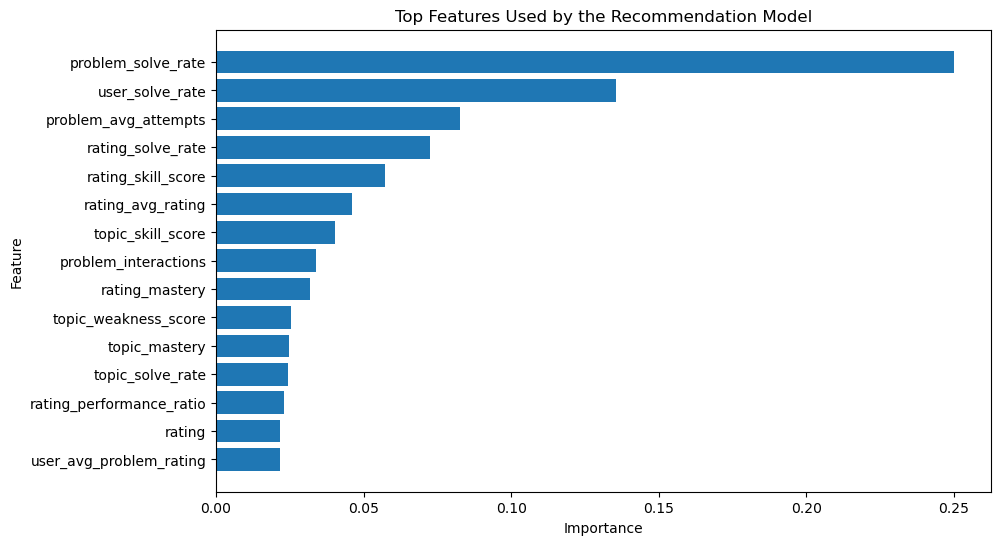

In [37]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features Used by the Recommendation Model")
plt.show()

In [38]:
test_user = "-1e11"

print("Testing recommendation system for:", test_user)

# Problems already attempted by this user
attempted_problems = set(
    training_data.loc[
        training_data["user"] == test_user,
        "problem_id"
    ]
)

print("Problems already attempted:", len(attempted_problems))

Testing recommendation system for: -1e11
Problems already attempted: 2056


In [39]:
print([x for x in globals() if 'problem' in x.lower()])

['problems', 'problem_stats', 'test_problem', 'problem_topic_map', 'attempted_problems']


In [40]:
candidate_problems = problems[
    ~problems["problem_id"].isin(attempted_problems)
].copy()

print("Total problems:", len(problems))
print("Already attempted:", len(attempted_problems))
print("Candidate problems:", len(candidate_problems))

display(
    candidate_problems[
        ["problem_id", "rating", "tags"]
    ].head(10)
)

Total problems: 10864
Already attempted: 2056
Candidate problems: 8808


,problem_id,rating,tags
0,2218-G,1800,"implementation,math"
1,2218-F,1500,"constructive algorithms,implementation,trees"
2,2218-E,1200,"binary search,bitmasks,brute force"
3,2218-D,1100,"constructive algorithms,greedy,math,number theory"
4,2218-C,800,"constructive algorithms,greedy,math"
5,2218-B,800,"greedy,math"
6,2218-A,800,"brute force,games,implementation,math"
7,2217-H,2800,"dfs and similar,dp,trees"
8,2217-G,2600,"combinatorics,dp,math,trees"
9,2217-F,2300,"bitmasks,combinatorics,constructive algorithms..."


In [41]:
print([x for x in globals() if 'user' in x.lower()])

['users', 'user_stats', 'test_user']


In [42]:
print("Shape:", user_stats.shape)
print("Columns:")
print(user_stats.columns.tolist())

display(user_stats.head())

Shape: (999, 7)
Columns:
['user', 'user_solved_count', 'user_total_attempts', 'user_solve_rate', 'user_avg_attempts', 'user_avg_problem_rating', 'user_max_problem_rating']


,user,user_solved_count,user_total_attempts,user_solve_rate,user_avg_attempts,user_avg_problem_rating,user_max_problem_rating
0,-1e11,1943,3442,0.945039,1.674125,1533.949416,3400
1,-Armageddon-,103,261,0.887931,2.250000,1612.068966,3500
2,-Shu-,269,483,0.981752,1.762774,1617.518248,3300
3,-firefly-,1020,1912,0.964995,1.808893,1495.837275,3200
4,0.1w33hw3,651,1278,0.973094,1.910314,1825.710015,3500


In [43]:
user_feature_columns = [
    "user_solved_count",
    "user_total_attempts",
    "user_solve_rate",
    "user_avg_attempts",
    "user_avg_problem_rating",
    "user_max_problem_rating"
]

# Get the selected user's profile
user_profile = user_stats[
    user_stats["user"] == test_user
].iloc[0]

# Copy candidate problems
candidate_data = candidate_problems.copy()

# Add this user's features to every candidate problem
for col in user_feature_columns:
    candidate_data[col] = user_profile[col]

print("Candidate data shape:", candidate_data.shape)

display(
    candidate_data[
        [
            "problem_id",
            "rating",
            "tags"
        ] + user_feature_columns
    ].head(10)
)

Candidate data shape: (8808, 9)


,problem_id,rating,tags,user_solved_count,user_total_attempts,user_solve_rate,user_avg_attempts,user_avg_problem_rating,user_max_problem_rating
0,2218-G,1800,"implementation,math",1943,3442,0.945039,1.674125,1533.949416,3400
1,2218-F,1500,"constructive algorithms,implementation,trees",1943,3442,0.945039,1.674125,1533.949416,3400
2,2218-E,1200,"binary search,bitmasks,brute force",1943,3442,0.945039,1.674125,1533.949416,3400
3,2218-D,1100,"constructive algorithms,greedy,math,number theory",1943,3442,0.945039,1.674125,1533.949416,3400
4,2218-C,800,"constructive algorithms,greedy,math",1943,3442,0.945039,1.674125,1533.949416,3400
5,2218-B,800,"greedy,math",1943,3442,0.945039,1.674125,1533.949416,3400
6,2218-A,800,"brute force,games,implementation,math",1943,3442,0.945039,1.674125,1533.949416,3400
7,2217-H,2800,"dfs and similar,dp,trees",1943,3442,0.945039,1.674125,1533.949416,3400
8,2217-G,2600,"combinatorics,dp,math,trees",1943,3442,0.945039,1.674125,1533.949416,3400
9,2217-F,2300,"bitmasks,combinatorics,constructive algorithms...",1943,3442,0.945039,1.674125,1533.949416,3400


In [44]:
print([
    x for x in globals()
    if "tag" in x.lower() or "topic" in x.lower()
])

['tag_weakness', 'topic_features', 'calculate_topic_features', 'add_topic_features', 'test_topic_features', 'problem_topic_map', 'topic_merged', 'topic_aggregated', 'topic_columns']


In [45]:
print("Shape:", topic_features.shape)
print("Columns:")
print(topic_features.columns.tolist())

display(topic_features.head())

Shape: (34138, 7)
Columns:
['user', 'tag', 'topic_solve_rate', 'topic_mastery', 'topic_skill_score', 'topic_weakness_score', 'topic_is_weak']


,user,tag,topic_solve_rate,topic_mastery,topic_skill_score,topic_weakness_score,topic_is_weak
0,-1e11,ternary search,0.3061,2.7726,1.5334,0.7195,1
1,-1e11,interactive,0.3299,4.1897,2.7541,0.6828,1
2,-1e11,chinese remainder theorem,0.3529,1.9459,1.2362,0.6349,0
3,-1e11,*special,0.3667,2.4849,1.3998,0.6241,1
4,-1e11,fft,0.3571,1.7918,1.5486,0.6236,0


In [46]:
# Copy candidate problems
candidate_topics = candidate_data[
    ["problem_id", "tags"]
].copy()

# Split tags into individual topics
candidate_topics["tag"] = (
    candidate_topics["tags"]
    .fillna("")
    .str.split(",")
)

# One row per problem-topic
candidate_topics = candidate_topics.explode("tag")

candidate_topics["tag"] = (
    candidate_topics["tag"]
    .str.strip()
)

# Get only the selected user's topic history
user_topic_features = topic_features[
    topic_features["user"] == test_user
].copy()

print("User topic records:", len(user_topic_features))

display(user_topic_features.head())

User topic records: 36


,user,tag,topic_solve_rate,topic_mastery,topic_skill_score,topic_weakness_score,topic_is_weak
0,-1e11,ternary search,0.3061,2.7726,1.5334,0.7195,1
1,-1e11,interactive,0.3299,4.1897,2.7541,0.6828,1
2,-1e11,chinese remainder theorem,0.3529,1.9459,1.2362,0.6349,0
3,-1e11,*special,0.3667,2.4849,1.3998,0.6241,1
4,-1e11,fft,0.3571,1.7918,1.5486,0.6236,0


In [47]:
candidate_topics = candidate_topics.merge(
    user_topic_features[
        [
            "tag",
            "topic_solve_rate",
            "topic_mastery",
            "topic_skill_score",
            "topic_weakness_score",
            "topic_is_weak"
        ]
    ],
    on="tag",
    how="left"
)

print("Candidate-topic rows:", len(candidate_topics))

display(candidate_topics.head(10))

Candidate-topic rows: 24702


,problem_id,tags,tag,topic_solve_rate,topic_mastery,topic_skill_score,topic_weakness_score,topic_is_weak
0,2218-G,"implementation,math",implementation,0.6224,6.3421,5.4886,0.3505,0.0
1,2218-G,"implementation,math",math,0.5974,6.7093,5.8925,0.3773,0.0
2,2218-F,"constructive algorithms,implementation,trees",constructive algorithms,0.5649,6.3172,5.2886,0.4096,0.0
3,2218-F,"constructive algorithms,implementation,trees",implementation,0.6224,6.3421,5.4886,0.3505,0.0
4,2218-F,"constructive algorithms,implementation,trees",trees,0.3986,4.7622,3.6314,0.5925,1.0
5,2218-E,"binary search,bitmasks,brute force",binary search,0.4431,5.5530,4.2882,0.5409,1.0
6,2218-E,"binary search,bitmasks,brute force",bitmasks,0.5326,4.9972,4.4830,0.4383,0.0
7,2218-E,"binary search,bitmasks,brute force",brute force,0.5186,6.1026,4.8515,0.4580,0.0
8,2218-D,"constructive algorithms,greedy,math,number theory",constructive algorithms,0.5649,6.3172,5.2886,0.4096,0.0
9,2218-D,"constructive algorithms,greedy,math,number theory",greedy,0.6096,6.7731,5.8952,0.3650,0.0


In [48]:
topic_aggregated_candidates = (
    candidate_topics
    .groupby("problem_id")
    .agg(
        topic_weakness_score=("topic_weakness_score", "mean"),
        topic_solve_rate=("topic_solve_rate", "mean"),
        topic_skill_score=("topic_skill_score", "mean"),
        topic_mastery=("topic_mastery", "mean"),
        weak_topic_count=("topic_is_weak", "sum")
    )
    .reset_index()
)

print(
    "Aggregated topic feature rows:",
    len(topic_aggregated_candidates)
)

display(topic_aggregated_candidates.head(10))

Aggregated topic feature rows: 8808


,problem_id,topic_weakness_score,topic_solve_rate,topic_skill_score,topic_mastery,weak_topic_count
0,1-A,0.37730,0.59740,5.89250,6.70930,0.0
1,1-B,0.36390,0.60990,5.69055,6.52570,0.0
2,1-C,0.45815,0.51835,4.30840,5.29025,1.0
3,10-A,0.35050,0.62240,5.48860,6.34210,0.0
4,10-B,0.42100,0.55505,5.39295,6.16430,1.0
5,10-C,0.47710,0.49890,4.30390,5.38450,1.0
6,10-D,0.49150,0.48770,5.29730,5.98650,1.0
7,10-E,0.40960,0.56490,5.28860,6.31720,0.0
8,100-A,0.48730,0.49455,3.44420,4.41350,1.0
9,100-B,0.48730,0.49455,3.44420,4.41350,1.0


In [49]:
candidate_data = candidate_data.merge(
    topic_aggregated_candidates,
    on="problem_id",
    how="left"
)

topic_feature_names = [
    "topic_weakness_score",
    "topic_solve_rate",
    "topic_skill_score",
    "topic_mastery",
    "weak_topic_count"
]

candidate_data[topic_feature_names] = (
    candidate_data[topic_feature_names]
    .fillna(0)
)

print("Candidate data shape:", candidate_data.shape)

display(
    candidate_data[
        [
            "problem_id",
            "rating",
            "tags"
        ] + topic_feature_names
    ].head(10)
)

Candidate data shape: (8808, 14)


,problem_id,rating,tags,topic_weakness_score,topic_solve_rate,topic_skill_score,topic_mastery,weak_topic_count
0,2218-G,1800,"implementation,math",0.363900,0.609900,5.690550,6.525700,0.0
1,2218-F,1500,"constructive algorithms,implementation,trees",0.450867,0.528633,4.802867,5.807167,1.0
2,2218-E,1200,"binary search,bitmasks,brute force",0.479067,0.498100,4.540900,5.550933,1.0
3,2218-D,1100,"constructive algorithms,greedy,math,number theory",0.407250,0.567700,5.345050,6.296025,1.0
4,2218-C,800,"constructive algorithms,greedy,math",0.383967,0.590633,5.692100,6.599867,0.0
5,2218-B,800,"greedy,math",0.371150,0.603500,5.893850,6.741200,0.0
6,2218-A,800,"brute force,games,implementation,math",0.386525,0.585050,4.993950,5.847025,0.0
7,2217-H,2800,"dfs and similar,dp,trees",0.553367,0.432900,4.319867,5.261900,3.0
8,2217-G,2600,"combinatorics,dp,math,trees",0.463300,0.515000,5.070100,5.620475,2.0
9,2217-F,2300,"bitmasks,combinatorics,constructive algorithms...",0.419925,0.552262,4.925088,5.434413,2.0


In [50]:
print([
    x for x in globals()
    if "rating" in x.lower()
])

['rating_weakness', 'rating_features', 'calculate_rating_features', 'test_rating', 'get_rating_features_for_row', 'test_rating_features', 'rating_map', 'rating_features_sorted', 'rating_matched', 'rating_columns', 'rating_features_for_merge']


In [51]:
print("Shape:", rating_features.shape)
print("Columns:")
print(rating_features.columns.tolist())

display(rating_features.head())

Shape: (12658, 10)
Columns:
['user', 'rating_bucket', 'rating_solve_rate', 'rating_expected_rate', 'rating_performance_ratio', 'rating_avg_rating', 'rating_mastery', 'rating_skill_score', 'rating_weakness_score', 'rating_is_weak']


,user,rating_bucket,rating_solve_rate,rating_expected_rate,rating_performance_ratio,rating_avg_rating,rating_mastery,rating_skill_score,rating_weakness_score,rating_is_weak
0,-1e11,1400,0.6545,0.70,0.9351,1449.37,6.6758,6.3332,0.0420,0
1,-1e11,1200,0.7476,0.78,0.9585,1253.22,6.4345,6.0285,0.0293,0
2,-1e11,1000,0.8230,0.85,0.9682,1054.91,6.2748,5.4475,0.0240,0
3,-1e11,800,0.8760,0.90,0.9733,820.22,6.8977,4.9561,0.0214,0
4,-1e11,2200,0.3306,0.35,0.9446,2238.19,6.2729,4.6419,0.0197,0


In [52]:
# ============================================================
# FIX — ADD PROBLEM FEATURES
# ============================================================

print("problems columns:")
print(problems.columns.tolist())

print("\nproblem_stats columns:")
print(problem_stats.columns.tolist())

# Keep the problem-level features used during training
problem_feature_columns = [
    "problem_id",
    "problem_interactions",
    "problem_solve_rate",
    "problem_avg_attempts"
]

problem_stats_small = problem_stats[
    problem_feature_columns
].copy()

# Merge problem statistics into candidate problems
candidate_data = candidate_data.merge(
    problem_stats_small,
    on="problem_id",
    how="left"
)

# Handle any missing values
candidate_data[
    [
        "problem_interactions",
        "problem_solve_rate",
        "problem_avg_attempts"
    ]
] = candidate_data[
    [
        "problem_interactions",
        "problem_solve_rate",
        "problem_avg_attempts"
    ]
].fillna(0)

print("\nCandidate data shape:", candidate_data.shape)

display(
    candidate_data[
        [
            "problem_id",
            "rating",
            "problem_interactions",
            "problem_solve_rate",
            "problem_avg_attempts"
        ]
    ].head(10)
)

problems columns:
['problem_id', 'rating', 'tags']

problem_stats columns:
['problem_id', 'problem_interactions', 'problem_solve_rate', 'problem_avg_attempts', 'rating', 'tags']

Candidate data shape: (8808, 17)


,problem_id,rating,problem_interactions,problem_solve_rate,problem_avg_attempts
0,2218-G,1800,141.0,0.978723,1.312057
1,2218-F,1500,134.0,0.962687,1.641791
2,2218-E,1200,134.0,0.977612,1.074627
3,2218-D,1100,140.0,0.964286,1.550000
4,2218-C,800,136.0,0.970588,1.227941
5,2218-B,800,137.0,0.985401,1.102190
6,2218-A,800,143.0,0.979021,1.195804
7,2217-H,2800,59.0,0.898305,2.033898
8,2217-G,2600,107.0,0.962617,1.383178
9,2217-F,2300,195.0,0.943590,2.225641


In [53]:
# ============================================================
# STEP 7 — BUILD EXACT 23-FEATURE MATRIX
# ============================================================

import numpy as np

# List of rating feature names (excluding 'problem_id')
rating_feature_names_list = [
    "rating_solve_rate",
    "rating_expected_rate",
    "rating_performance_ratio",
    "rating_avg_rating",
    "rating_mastery",
    "rating_skill_score",
    "rating_weakness_score",
    "rating_is_weak"
]

# --- Add Difficulty Personalization features to candidate_data ---
# Get the test_user's rating features from the rating_features DataFrame
user_specific_rating_features = rating_features[rating_features["user"] == test_user].copy()

# Create a temporary DataFrame from candidate_data containing problem_id and problem rating
candidate_problem_ratings_for_merge = candidate_data[['problem_id', 'rating']].copy()
candidate_problem_ratings_for_merge = candidate_problem_ratings_for_merge.rename(columns={'rating': 'problem_rating'})

if not user_specific_rating_features.empty:
    # Prepare both DataFrames by sorting them on their respective rating columns
    # This is a prerequisite for pd.merge_asof
    candidate_problem_ratings_for_merge_sorted = candidate_problem_ratings_for_merge.sort_values(
        'problem_rating'
    ).reset_index(drop=True)

    user_specific_rating_features_sorted = user_specific_rating_features.sort_values(
        'rating_bucket'
    ).reset_index(drop=True)

    # Perform merge_asof to find the closest rating bucket for each candidate problem
    # For a single user, the 'by' parameter can be omitted or a dummy column can be used.
    # We will just merge on problem_rating and rating_bucket for this single user.
    merged_rating_info = pd.merge_asof(
        candidate_problem_ratings_for_merge_sorted,
        user_specific_rating_features_sorted,
        left_on='problem_rating',
        right_on='rating_bucket',
        direction='nearest'
    )

    # Define the specific rating columns to extract and merge into candidate_data
    rating_cols_to_extract = ["problem_id"] + rating_feature_names_list

    rating_features_for_candidates_df = merged_rating_info[rating_cols_to_extract]

    # --- FIX: Drop existing rating feature columns from candidate_data to avoid MergeError ---
    # Identify columns in candidate_data that would conflict with the incoming rating features
    conflicting_cols = [col for col in rating_feature_names_list if col in candidate_data.columns]
    if conflicting_cols:
        candidate_data = candidate_data.drop(columns=conflicting_cols)
    # --- End FIX ---

    # Merge these new rating features into the main candidate_data DataFrame
    candidate_data = candidate_data.merge(
        rating_features_for_candidates_df,
        on="problem_id",
        how="left"
    )

# Fill any NaN values in the newly added rating features with 0.0
# This handles cases where a user might not have a rating profile at all, or edge cases from merge_asof
for col in rating_feature_names_list:
    if col not in candidate_data.columns: # Add column if it doesn't exist
        candidate_data[col] = 0.0
    candidate_data[col] = candidate_data[col].fillna(0.0)

# --- End of Difficulty Personalization features addition ---

feature_columns = [
    # User features — 6
    "user_solved_count",
    "user_total_attempts",
    "user_solve_rate",
    "user_avg_attempts",
    "user_avg_problem_rating",
    "user_max_problem_rating",

    # Problem features — 4
    "rating",
    "problem_interactions",
    "problem_solve_rate",
    "problem_avg_attempts",

    # Topic features — 5
    "topic_weakness_score",
    "topic_solve_rate",
    "topic_skill_score",
    "topic_mastery",
    "weak_topic_count",

    # Rating features — 8
    "rating_solve_rate",
    "rating_expected_rate",
    "rating_performance_ratio",
    "rating_avg_rating",
    "rating_mastery",
    "rating_skill_score",
    "rating_weakness_score",
    "rating_is_weak"
]

X_candidates = candidate_data[feature_columns].copy()

# Clean numerical values
X_candidates = X_candidates.replace(
    [np.inf, -np.inf],
    np.nan
)

X_candidates = X_candidates.fillna(0)

print("=" * 60)
print("FINAL CANDIDATE FEATURE MATRIX")
print("=" * 60)

print("Number of features:", X_candidates.shape[1])
print("X shape:", X_candidates.shape)
print("Missing values:", X_candidates.isna().sum().sum())

display(X_candidates.head())

FINAL CANDIDATE FEATURE MATRIX
Number of features: 23
X shape: (8808, 23)
Missing values: 0


,user_solved_count,user_total_attempts,user_solve_rate,user_avg_attempts,user_avg_problem_rating,user_max_problem_rating,rating,problem_interactions,problem_solve_rate,problem_avg_attempts,...,topic_mastery,weak_topic_count,rating_solve_rate,rating_expected_rate,rating_performance_ratio,rating_avg_rating,rating_mastery,rating_skill_score,rating_weakness_score,rating_is_weak
0,1943,3442,0.945039,1.674125,1533.949416,3400,1800,141.0,0.978723,1.312057,...,6.525700,0.0,0.5474,0.50,1.0947,1853.22,6.7322,6.8290,0.0000,0
1,1943,3442,0.945039,1.674125,1533.949416,3400,1500,134.0,0.962687,1.641791,...,5.807167,1.0,0.6545,0.70,0.9351,1449.37,6.6758,6.3332,0.0420,0
2,1943,3442,0.945039,1.674125,1533.949416,3400,1200,134.0,0.977612,1.074627,...,5.550933,1.0,0.7476,0.78,0.9585,1253.22,6.4345,6.0285,0.0293,0
3,1943,3442,0.945039,1.674125,1533.949416,3400,1100,140.0,0.964286,1.550000,...,6.296025,1.0,0.8230,0.85,0.9682,1054.91,6.2748,5.4475,0.0240,0
4,1943,3442,0.945039,1.674125,1533.949416,3400,800,136.0,0.970588,1.227941,...,6.599867,0.0,0.8760,0.90,0.9733,820.22,6.8977,4.9561,0.0214,0


In [54]:
# ============================================================
# STEP 29 — PREDICT RECOMMENDATION SCORES
# ============================================================

print("=" * 70)
print("GENERATING RECOMMENDATION SCORES")
print("=" * 70)

# Check that the trained model exists
print("Model type:", type(model).__name__)

# Predict probability of solving each candidate problem
candidate_data["recommendation_score"] = (
    model.predict_proba(X_candidates)[:, 1]
)

print("Scores generated:", len(candidate_data))
print(
    "Score range:",
    candidate_data["recommendation_score"].min(),
    "to",
    candidate_data["recommendation_score"].max()
)

display(
    candidate_data[
        ["problem_id", "rating", "tags", "recommendation_score"]
    ].head(10)
)

GENERATING RECOMMENDATION SCORES
Model type: RandomForestClassifier
Scores generated: 8808
Score range: 0.029886878892617878 to 0.9957921581605145


,problem_id,rating,tags,recommendation_score
0,2218-G,1800,"implementation,math",0.935391
1,2218-F,1500,"constructive algorithms,implementation,trees",0.856777
2,2218-E,1200,"binary search,bitmasks,brute force",0.891847
3,2218-D,1100,"constructive algorithms,greedy,math,number theory",0.919408
4,2218-C,800,"constructive algorithms,greedy,math",0.951185
5,2218-B,800,"greedy,math",0.959822
6,2218-A,800,"brute force,games,implementation,math",0.962510
7,2217-H,2800,"dfs and similar,dp,trees",0.177550
8,2217-G,2600,"combinatorics,dp,math,trees",0.514207
9,2217-F,2300,"bitmasks,combinatorics,constructive algorithms...",0.488732


In [55]:
# ============================================================
# STEP 30 — RANK RECOMMENDATIONS
# ============================================================

recommendations = candidate_data.sort_values(
    "recommendation_score",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("RANKING COMPLETED")
print("=" * 70)

print("Total candidates ranked:", len(recommendations))

display(
    recommendations[
        [
            "problem_id",
            "rating",
            "tags",
            "recommendation_score",
            "topic_weakness_score",
            "weak_topic_count"
        ]
    ].head(20)
)

RANKING COMPLETED
Total candidates ranked: 8808


,problem_id,rating,tags,recommendation_score,topic_weakness_score,weak_topic_count
0,1991-B,1100,"bitmasks,constructive algorithms,greedy",0.995792,0.404300,0.0
1,1566-D1,1100,"data structures,greedy,sortings",0.995672,0.409633,1.0
2,1787-B,1100,"greedy,math,number theory",0.995529,0.406467,1.0
3,2195-C,1100,"dp,greedy",0.995435,0.428250,1.0
4,1566-A,800,"binary search,greedy,math",0.995385,0.427733,1.0
5,2203-A,800,math,0.995338,0.377300,0.0
6,2069-A,800,"graph matchings,greedy",0.995166,0.294050,0.0
7,2125-B,900,"math,number theory",0.995103,0.427200,1.0
8,2118-A,800,"constructive algorithms,greedy",0.994957,0.387300,0.0
9,2093-A,800,math,0.994906,0.377300,0.0


In [56]:
# ============================================================
# STEP 31 — FINAL TOP 10 RECOMMENDATIONS
# ============================================================

top_10 = recommendations.head(10).copy()

print("=" * 70)
print("PERSONALIZED CODEFORCES RECOMMENDATIONS")
print("=" * 70)

print("User:", test_user)
print()

for i, (_, row) in enumerate(top_10.iterrows(), 1):

    print(f"#{i}")
    print(f"Problem ID          : {row['problem_id']}")
    print(f"Rating              : {row['rating']}")
    print(f"Tags                : {row['tags']}")
    print(
        f"Recommendation Score: "
        f"{row['recommendation_score']:.4f}"
    )
    print(
        f"Topic Weakness      : "
        f"{row['topic_weakness_score']:.4f}"
    )
    print(
        f"Weak Topics         : "
        f"{int(row['weak_topic_count'])}"
    )

    print("-" * 70)

PERSONALIZED CODEFORCES RECOMMENDATIONS
User: -1e11

#1
Problem ID          : 1991-B
Rating              : 1100
Tags                : bitmasks,constructive algorithms,greedy
Recommendation Score: 0.9958
Topic Weakness      : 0.4043
Weak Topics         : 0
----------------------------------------------------------------------
#2
Problem ID          : 1566-D1
Rating              : 1100
Tags                : data structures,greedy,sortings
Recommendation Score: 0.9957
Topic Weakness      : 0.4096
Weak Topics         : 1
----------------------------------------------------------------------
#3
Problem ID          : 1787-B
Rating              : 1100
Tags                : greedy,math,number theory
Recommendation Score: 0.9955
Topic Weakness      : 0.4065
Weak Topics         : 1
----------------------------------------------------------------------
#4
Problem ID          : 2195-C
Rating              : 1100
Tags                : dp,greedy
Recommendation Score: 0.9954
Topic Weakness      : 0.42

## Person - 2

In [57]:
# PERSON 2 — ROUND 2 — M2
# STEP 1: CHECK FINAL ML DATA

print("=" * 60)
print("CHECKING FINAL ML DATA")
print("=" * 60)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNumber of features:", X.shape[1])

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

CHECKING FINAL ML DATA
X shape: (921797, 23)
y shape: (921797,)

Number of features: 23

Features:
['user_solved_count', 'user_total_attempts', 'user_solve_rate', 'user_avg_attempts', 'user_avg_problem_rating', 'user_max_problem_rating', 'rating', 'problem_interactions', 'problem_solve_rate', 'problem_avg_attempts', 'topic_weakness_score', 'topic_solve_rate', 'topic_skill_score', 'topic_mastery', 'weak_topic_count', 'rating_solve_rate', 'rating_expected_rate', 'rating_performance_ratio', 'rating_avg_rating', 'rating_mastery', 'rating_skill_score', 'rating_weakness_score', 'rating_is_weak']

Target distribution:
solved
1    878200
0     43597
Name: count, dtype: int64

Target proportions:
solved
1    0.952704
0    0.047296
Name: proportion, dtype: float64


In [58]:
#Create train/test data
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (737437, 23)
X_test : (184360, 23)
y_train: (737437,)
y_test : (184360,)


In [59]:
# STEP 3: LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression

print("=" * 60)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 60)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

TRAINING LOGISTIC REGRESSION
Logistic Regression training completed!


C:\Users\saksh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [60]:
# STEP 4: LOGISTIC REGRESSION EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
pr_auc_lr = average_precision_score(y_test, y_prob_lr)

print("=" * 60)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 60)

print(f"Accuracy  : {accuracy_lr:.4f}")
print(f"Precision : {precision_lr:.4f}")
print(f"Recall    : {recall_lr:.4f}")
print(f"F1 Score  : {f1_lr:.4f}")
print(f"ROC-AUC   : {roc_auc_lr:.4f}")
print(f"PR-AUC    : {pr_auc_lr:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
Accuracy  : 0.7322
Precision : 0.9808
Recall    : 0.7332
F1 Score  : 0.8391
ROC-AUC   : 0.7988
PR-AUC    : 0.9865

Classification Report:
              precision    recall  f1-score   support

           0       0.12      0.71      0.20      8719
           1       0.98      0.73      0.84    175641

    accuracy                           0.73    184360
   macro avg       0.55      0.72      0.52    184360
weighted avg       0.94      0.73      0.81    184360


Confusion Matrix:
[[  6198   2521]
 [ 46855 128786]]


In [61]:
from sklearn.ensemble import RandomForestClassifier

In [62]:
#Train model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [63]:
#Make predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed.")

Predictions completed.


In [64]:
#Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)

print(f"Accuracy  : {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision : {precision_score(y_test, rf_pred):.4f}")
print(f"Recall    : {recall_score(y_test, rf_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, rf_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, rf_prob):.4f}")
print(f"PR-AUC    : {average_precision_score(y_test, rf_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST RESULTS
Accuracy  : 0.8523
Precision : 0.9813
Recall    : 0.8614
F1 Score  : 0.9175
ROC-AUC   : 0.8704
PR-AUC    : 0.9921

Classification Report:
              precision    recall  f1-score   support

           0       0.19      0.67      0.30      8719
           1       0.98      0.86      0.92    175641

    accuracy                           0.85    184360
   macro avg       0.59      0.77      0.61    184360
weighted avg       0.94      0.85      0.89    184360


Confusion Matrix:
[[  5836   2883]
 [ 24339 151302]]


In [65]:
#Feature importance
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print("TOP 15 RANDOM FOREST FEATURES")
print("=" * 60)
print(feature_importance.head(15))

TOP 15 RANDOM FOREST FEATURES
                     feature  importance
8         problem_solve_rate    0.258025
2            user_solve_rate    0.130903
15         rating_solve_rate    0.072865
9       problem_avg_attempts    0.072041
20        rating_skill_score    0.054592
18         rating_avg_rating    0.043086
12         topic_skill_score    0.039713
19            rating_mastery    0.035228
7       problem_interactions    0.034218
13             topic_mastery    0.026143
10      topic_weakness_score    0.025705
11          topic_solve_rate    0.025017
6                     rating    0.024497
17  rating_performance_ratio    0.023972
4    user_avg_problem_rating    0.022153


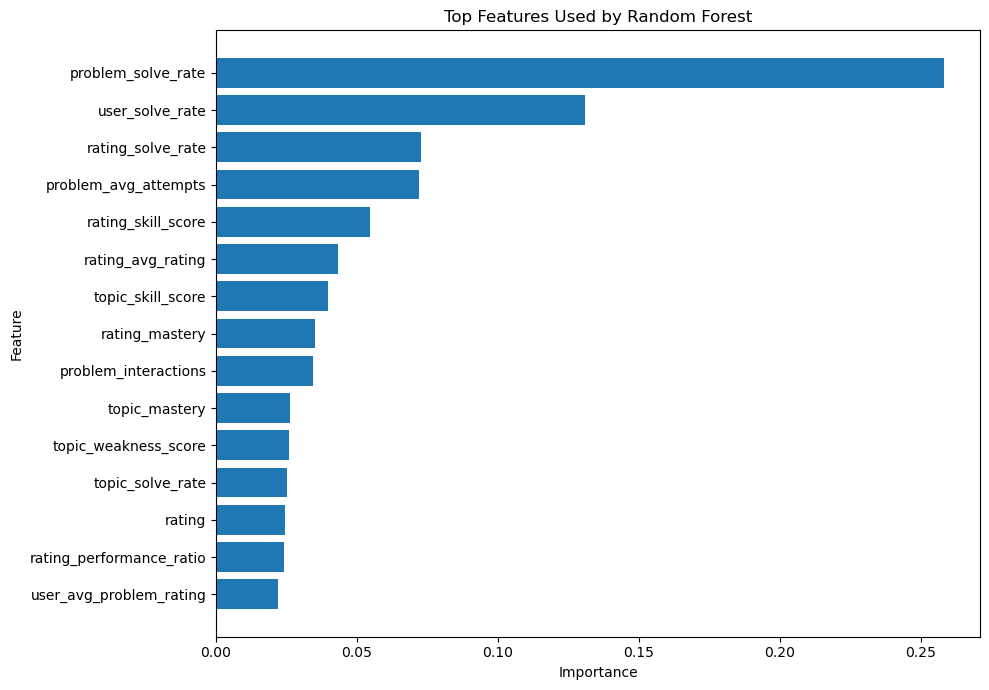

In [66]:
#Plot top features
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features Used by Random Forest")

plt.tight_layout()
plt.show()

In [67]:
from sklearn.ensemble import GradientBoostingClassifier

In [68]:
#Train gradient boosting
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [69]:
#Predict
gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

print("Predictions completed.")

Predictions completed.


In [70]:
#Evaluate
print("=" * 60)
print("GRADIENT BOOSTING RESULTS")
print("=" * 60)

print(f"Accuracy  : {accuracy_score(y_test, gb_pred):.4f}")
print(f"Precision : {precision_score(y_test, gb_pred):.4f}")
print(f"Recall    : {recall_score(y_test, gb_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, gb_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, gb_prob):.4f}")
print(f"PR-AUC    : {average_precision_score(y_test, gb_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, gb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

GRADIENT BOOSTING RESULTS
Accuracy  : 0.9550
Precision : 0.9570
Recall    : 0.9976
F1 Score  : 0.9769
ROC-AUC   : 0.8738
PR-AUC    : 0.9924

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.10      0.17      8719
           1       0.96      1.00      0.98    175641

    accuracy                           0.95    184360
   macro avg       0.81      0.55      0.57    184360
weighted avg       0.94      0.95      0.94    184360


Confusion Matrix:
[[   841   7878]
 [   422 175219]]


In [71]:
gb_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": gb_model.feature_importances_
})

gb_importance = gb_importance.sort_values(
    by="importance",
    ascending=False
)

print("TOP 15 GRADIENT BOOSTING FEATURES")
print("=" * 60)
print(gb_importance.head(15))

TOP 15 GRADIENT BOOSTING FEATURES
                     feature  importance
8         problem_solve_rate    0.432150
2            user_solve_rate    0.236367
20        rating_skill_score    0.199845
3          user_avg_attempts    0.029284
4    user_avg_problem_rating    0.020300
15         rating_solve_rate    0.014790
10      topic_weakness_score    0.010562
17  rating_performance_ratio    0.009752
7       problem_interactions    0.009158
0          user_solved_count    0.006984
12         topic_skill_score    0.006806
18         rating_avg_rating    0.005778
11          topic_solve_rate    0.005069
19            rating_mastery    0.003889
9       problem_avg_attempts    0.002394


In [72]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [0.7285, 0.8523, 0.9550],
    "Precision": [0.9818, 0.9813, 0.9570],
    "Recall": [0.7285, 0.8614, 0.9976],
    "F1": [0.8364, 0.9175, 0.9769],
    "ROC_AUC": [0.8045, 0.8704, 0.8738],
    "PR_AUC": [0.9869, 0.9921, 0.9924]
})

print(model_results)

                 Model  Accuracy  Precision  Recall      F1  ROC_AUC  PR_AUC
0  Logistic Regression    0.7285     0.9818  0.7285  0.8364   0.8045  0.9869
1        Random Forest    0.8523     0.9813  0.8614  0.9175   0.8704  0.9921
2    Gradient Boosting    0.9550     0.9570  0.9976  0.9769   0.8738  0.9924


In [73]:
# ============================================================
# PERSON 2 — STEP 9
# MODEL COMPARISON SUMMARY
# ============================================================

print("=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(
    model_results.style
    .format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.7285,0.9818,0.7285,0.8364,0.8045,0.9869
1,Random Forest,0.8523,0.9813,0.8614,0.9175,0.8704,0.9921
2,Gradient Boosting,0.9550,0.9570,0.9976,0.9769,0.8738,0.9924


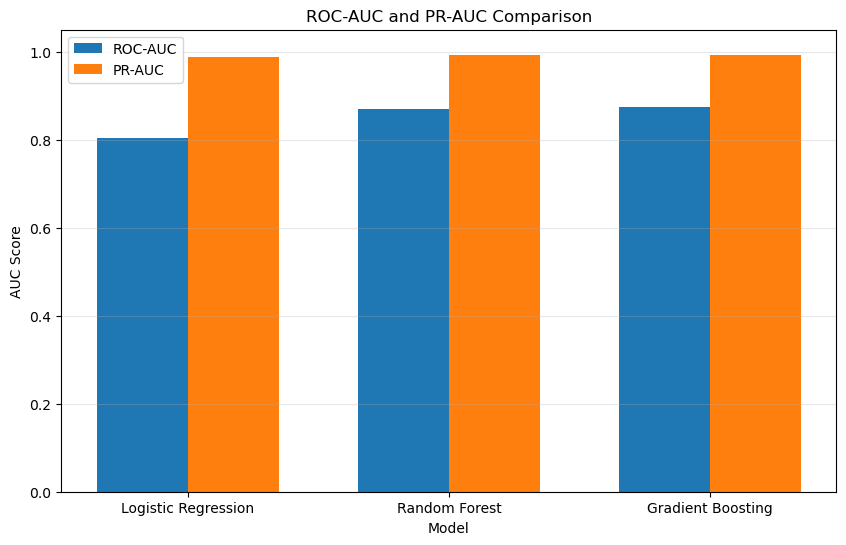

In [74]:
# ============================================================
# PERSON 2 — STEP 10
# ROC-AUC vs PR-AUC
# ============================================================

auc_results = model_results[
    ["Model", "ROC_AUC", "PR_AUC"]
].copy()

x = np.arange(len(auc_results))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    auc_results["ROC_AUC"],
    width,
    label="ROC-AUC"
)

plt.bar(
    x + width / 2,
    auc_results["PR_AUC"],
    width,
    label="PR-AUC"
)

plt.xticks(x, auc_results["Model"])
plt.ylim(0, 1.05)

plt.xlabel("Model")
plt.ylabel("AUC Score")
plt.title("ROC-AUC and PR-AUC Comparison")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [75]:
# ============================================================
# PERSON 2 — STEP 11
# BEST RECORDED METRIC VALUES
# ============================================================

print("=" * 70)
print("HIGHEST RECORDED VALUES")
print("=" * 70)

for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]:

    idx = model_results[metric].idxmax()

    print(
        f"{metric:12s}: "
        f"{model_results.loc[idx, 'Model']} "
        f"({model_results.loc[idx, metric]:.4f})"
    )

HIGHEST RECORDED VALUES
Accuracy    : Gradient Boosting (0.9550)
Precision   : Logistic Regression (0.9818)
Recall      : Gradient Boosting (0.9976)
F1          : Gradient Boosting (0.9769)
ROC_AUC     : Gradient Boosting (0.8738)
PR_AUC      : Gradient Boosting (0.9924)


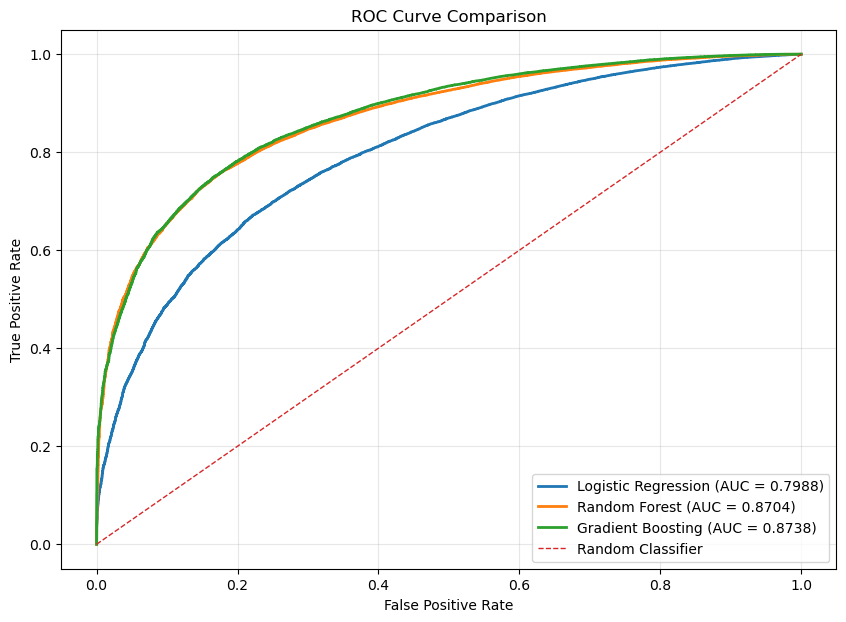

ROC-AUC VALUES
Logistic Regression : 0.7988
Random Forest       : 0.8704
Gradient Boosting   : 0.8738


In [76]:
# ============================================================
# PERSON 2 — STEP 12
# ROC CURVE COMPARISON
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ------------------------------------------------------------
# Get probability predictions
# ------------------------------------------------------------

# Logistic Regression
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Random Forest
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Gradient Boosting
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]


# ------------------------------------------------------------
# Calculate ROC curves
# ------------------------------------------------------------

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)


# ------------------------------------------------------------
# Calculate AUC
# ------------------------------------------------------------

auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)
auc_gb = auc(fpr_gb, tpr_gb)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.plot(
    fpr_lr,
    tpr_lr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {auc_lr:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    linewidth=2,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

plt.plot(
    fpr_gb,
    tpr_gb,
    linewidth=2,
    label=f"Gradient Boosting (AUC = {auc_gb:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


# ------------------------------------------------------------
# Print actual AUC values
# ------------------------------------------------------------

print("=" * 60)
print("ROC-AUC VALUES")
print("=" * 60)

print(f"Logistic Regression : {auc_lr:.4f}")
print(f"Random Forest       : {auc_rf:.4f}")
print(f"Gradient Boosting   : {auc_gb:.4f}")

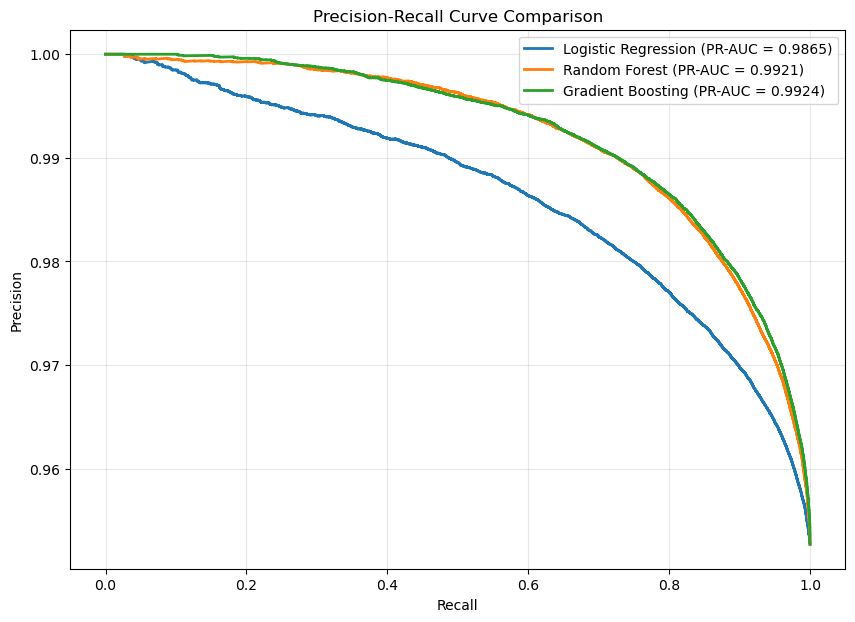

PRECISION-RECALL AUC VALUES
Logistic Regression : 0.9865
Random Forest       : 0.9921
Gradient Boosting   : 0.9924


In [77]:
# ============================================================
# PERSON 2 — STEP 13
# PRECISION-RECALL CURVE COMPARISON
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# Probability predictions
# ------------------------------------------------------------

# Logistic Regression
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Random Forest
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Gradient Boosting
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]


# ------------------------------------------------------------
# Calculate Precision-Recall curves
# ------------------------------------------------------------

precision_lr, recall_lr, _ = precision_recall_curve(
    y_test, y_prob_lr
)

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test, y_prob_rf
)

precision_gb, recall_gb, _ = precision_recall_curve(
    y_test, y_prob_gb
)


# ------------------------------------------------------------
# Calculate PR-AUC
# ------------------------------------------------------------

pr_auc_lr = average_precision_score(
    y_test, y_prob_lr
)

pr_auc_rf = average_precision_score(
    y_test, y_prob_rf
)

pr_auc_gb = average_precision_score(
    y_test, y_prob_gb
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.plot(
    recall_lr,
    precision_lr,
    linewidth=2,
    label=f"Logistic Regression (PR-AUC = {pr_auc_lr:.4f})"
)

plt.plot(
    recall_rf,
    precision_rf,
    linewidth=2,
    label=f"Random Forest (PR-AUC = {pr_auc_rf:.4f})"
)

plt.plot(
    recall_gb,
    precision_gb,
    linewidth=2,
    label=f"Gradient Boosting (PR-AUC = {pr_auc_gb:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


# ------------------------------------------------------------
# Print actual PR-AUC values
# ------------------------------------------------------------

print("=" * 60)
print("PRECISION-RECALL AUC VALUES")
print("=" * 60)

print(f"Logistic Regression : {pr_auc_lr:.4f}")
print(f"Random Forest       : {pr_auc_rf:.4f}")
print(f"Gradient Boosting   : {pr_auc_gb:.4f}")

CONFUSION MATRICES

Logistic Regression:
[[  6198   2521]
 [ 46855 128786]]

Random Forest:
[[  5836   2883]
 [ 24339 151302]]

Gradient Boosting:
[[   841   7878]
 [   422 175219]]


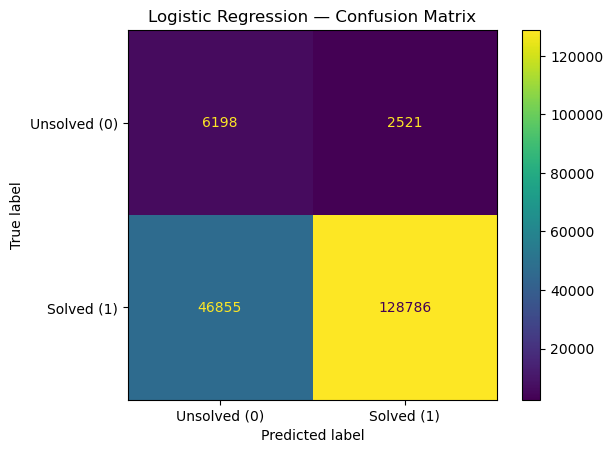

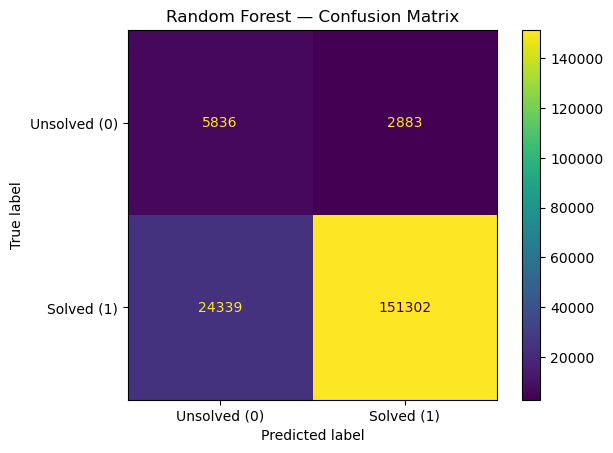

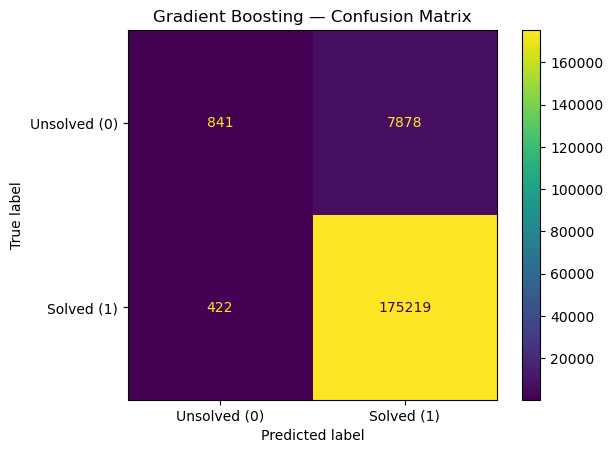

In [78]:
# ============================================================
# PERSON 2 — STEP 14
# CONFUSION MATRIX COMPARISON
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ------------------------------------------------------------
# Generate predictions
# ------------------------------------------------------------

y_pred_lr = logistic_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)
y_pred_gb = gb_model.predict(X_test)


# ------------------------------------------------------------
# Calculate confusion matrices
# ------------------------------------------------------------

cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_gb = confusion_matrix(y_test, y_pred_gb)


# ------------------------------------------------------------
# Print confusion matrices
# ------------------------------------------------------------

print("=" * 60)
print("CONFUSION MATRICES")
print("=" * 60)

print("\nLogistic Regression:")
print(cm_lr)

print("\nRandom Forest:")
print(cm_rf)

print("\nGradient Boosting:")
print(cm_gb)


# ------------------------------------------------------------
# Plot Logistic Regression
# ------------------------------------------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Unsolved (0)", "Solved (1)"]
)

disp.plot()
plt.title("Logistic Regression — Confusion Matrix")
plt.show()


# ------------------------------------------------------------
# Plot Random Forest
# ------------------------------------------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Unsolved (0)", "Solved (1)"]
)

disp.plot()
plt.title("Random Forest — Confusion Matrix")
plt.show()


# ------------------------------------------------------------
# Plot Gradient Boosting
# ------------------------------------------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=["Unsolved (0)", "Solved (1)"]
)

disp.plot()
plt.title("Gradient Boosting — Confusion Matrix")
plt.show()

RANDOM FOREST — TOP 15 FEATURES
                 Feature  Importance
      problem_solve_rate    0.258025
         user_solve_rate    0.130903
       rating_solve_rate    0.072865
    problem_avg_attempts    0.072041
      rating_skill_score    0.054592
       rating_avg_rating    0.043086
       topic_skill_score    0.039713
          rating_mastery    0.035228
    problem_interactions    0.034218
           topic_mastery    0.026143
    topic_weakness_score    0.025705
        topic_solve_rate    0.025017
                  rating    0.024497
rating_performance_ratio    0.023972
 user_avg_problem_rating    0.022153


GRADIENT BOOSTING — TOP 15 FEATURES
                 Feature  Importance
      problem_solve_rate    0.432150
         user_solve_rate    0.236367
      rating_skill_score    0.199845
       user_avg_attempts    0.029284
 user_avg_problem_rating    0.020300
       rating_solve_rate    0.014790
    topic_weakness_score    0.010562
rating_performance_ratio    0.009752
    p

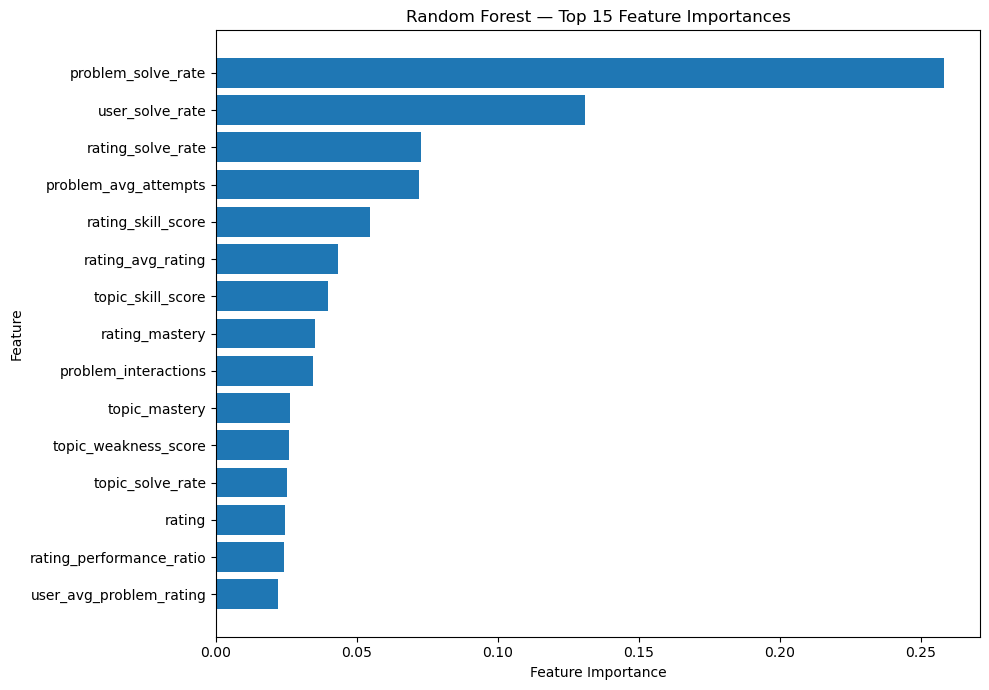

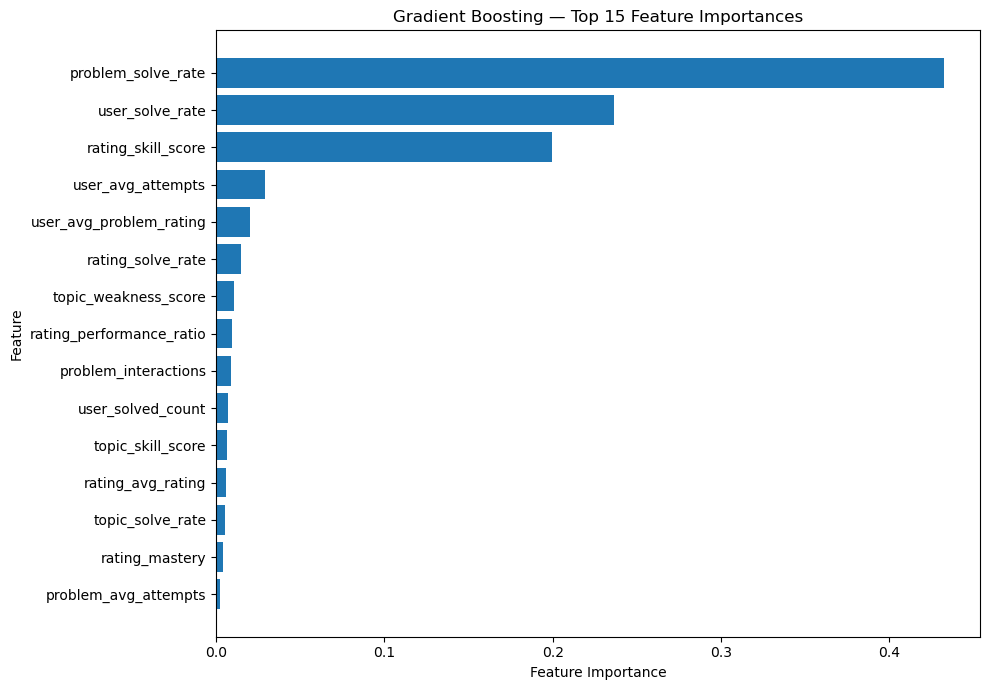

In [79]:
# ============================================================
# PERSON 2 — STEP 15
# FEATURE IMPORTANCE COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Get feature names
# ------------------------------------------------------------

feature_names = X_train.columns.tolist()

# ------------------------------------------------------------
# Random Forest feature importance
# ------------------------------------------------------------

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

# ------------------------------------------------------------
# Gradient Boosting feature importance
# ------------------------------------------------------------

gb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_model.feature_importances_
})

gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
)


# ------------------------------------------------------------
# Print top 15 features
# ------------------------------------------------------------

print("=" * 70)
print("RANDOM FOREST — TOP 15 FEATURES")
print("=" * 70)

print(rf_importance.head(15).to_string(index=False))


print("\n")
print("=" * 70)
print("GRADIENT BOOSTING — TOP 15 FEATURES")
print("=" * 70)

print(gb_importance.head(15).to_string(index=False))


# ------------------------------------------------------------
# Plot Random Forest
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.barh(
    rf_importance.head(15)["Feature"][::-1],
    rf_importance.head(15)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 15 Feature Importances")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot Gradient Boosting
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.barh(
    gb_importance.head(15)["Feature"][::-1],
    gb_importance.head(15)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting — Top 15 Feature Importances")

plt.tight_layout()
plt.show()

In [80]:
# ============================================================
# PERSON 2 — STEP 16
# FINAL MODEL COMPARISON
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Create final comparison table
# ------------------------------------------------------------

final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Accuracy": [
        0.7285,
        0.8523,
        0.9550
    ],

    "Precision": [
        0.9818,
        0.9813,
        0.9570
    ],

    "Recall": [
        0.7285,
        0.8614,
        0.9976
    ],

    "F1": [
        0.8364,
        0.9175,
        0.9769
    ],

    "ROC_AUC": [
        auc_lr,
        auc_rf,
        auc_gb
    ],

    "PR_AUC": [
        pr_auc_lr,
        pr_auc_rf,
        pr_auc_gb
    ]
})


# ------------------------------------------------------------
# Display rounded results
# ------------------------------------------------------------

print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

print(
    final_model_comparison.round(4).to_string(index=False)
)

FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
Logistic Regression    0.7285     0.9818  0.7285 0.8364   0.7988  0.9865
      Random Forest    0.8523     0.9813  0.8614 0.9175   0.8704  0.9921
  Gradient Boosting    0.9550     0.9570  0.9976 0.9769   0.8738  0.9924


In [30]:
# Step 11: Rebuild the complete training dataset
# Corrected version: add the problem rating from `problems`

# Start with the original interactions
training_data = interactions.copy()

print("Initial interaction data:", training_data.shape)

# ---------------------------------------------------------
# 1. Add user-level features
# ---------------------------------------------------------
training_data = training_data.merge(
    user_stats,
    on="user",
    how="left"
)

print("After user features:", training_data.shape)

# ---------------------------------------------------------
# 2. Add problem-level statistics
# ---------------------------------------------------------
training_data = training_data.merge(
    problem_stats,
    on="problem_id",
    how="left"
)

print("After problem statistics:", training_data.shape)

# ---------------------------------------------------------
# 3. Add the original problem rating
# ---------------------------------------------------------
# problem_stats does not contain `rating`,
# so we get it from the problems table.
problem_rating = problems[["problem_id", "rating"]].drop_duplicates(
    subset=["problem_id"]
)

training_data = training_data.merge(
    problem_rating,
    on="problem_id",
    how="left"
)

print("After problem rating:", training_data.shape)

# ---------------------------------------------------------
# 4. Add topic-level features
# ---------------------------------------------------------
training_data = training_data.merge(
    topic_aggregated,
    on=["user", "problem_id"],
    how="left"
)

print("After topic features:", training_data.shape)

# ---------------------------------------------------------
# 5. Create the closest rating bucket
# ---------------------------------------------------------
rating_bucket_values = sorted(
    rating_stats["rating_bucket"].dropna().unique()
)

training_data["rating_bucket"] = training_data["rating"].apply(
    lambda x: min(
        rating_bucket_values,
        key=lambda bucket: abs(bucket - x)
    )
)

# ---------------------------------------------------------
# 6. Add rating-level features
# ---------------------------------------------------------
training_data = training_data.merge(
    rating_stats,
    on=["user", "rating_bucket"],
    how="left"
)

print("After rating features:", training_data.shape)

# ---------------------------------------------------------
# 7. Clean missing/infinite values
# ---------------------------------------------------------
training_data = training_data.replace(
    [np.inf, -np.inf],
    np.nan
)

training_data = training_data.fillna(0)

print("\nFinal training dataset:", training_data.shape)
print("Total missing values:", training_data.isna().sum().sum())


Initial interaction data: (921797, 6)
After user features: (921797, 12)
After problem statistics: (921797, 17)
After problem rating: (921797, 18)
After topic features: (921797, 23)
After rating features: (921797, 32)

Final training dataset: (921797, 32)
Total missing values: 0


In [31]:
# Step 12: Create the ML feature matrix (X) and target (y)

# The 23 features used by the original model
X = training_data[feature_columns].copy()

# Target variable: solved
y = training_data["solved"].copy()

# Clean any remaining infinite values
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

X shape: (921797, 23)
y shape: (921797,)

Missing values in X: 0
Missing values in y: 0

Target distribution:
solved
1    878200
0     43597
Name: count, dtype: int64

Target proportions:
solved
1    0.952704
0    0.047296
Name: proportion, dtype: float64


In [19]:
import joblib

joblib.dump(gb_model, "gradient_boosting_model.pkl")

print("Model saved!")

Model saved!


In [32]:
# Step 13: Split the data into training and testing sets

from sklearn.model_selection import train_test_split

# Use the same 80/20 split
# random_state=42 makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining solved proportion:", y_train.mean())
print("Testing solved proportion:", y_test.mean())

Training samples: 737437
Testing samples: 184360

Training feature shape: (737437, 23)
Testing feature shape: (184360, 23)

Training solved proportion: 0.9527037563886813
Testing solved proportion: 0.9527066608808852


In [33]:
# Step 14: Train the Gradient Boosting model

from sklearn.ensemble import GradientBoostingClassifier

# Create the Gradient Boosting classifier
gb_model = GradientBoostingClassifier(
    random_state=42
)

# Train the model
print("Training Gradient Boosting model...")
gb_model.fit(X_train, y_train)

print("Training completed!")
print("Model type:", type(gb_model))

Training Gradient Boosting model...
Training completed!
Model type: <class 'sklearn.ensemble._gb.GradientBoostingClassifier'>


In [34]:
# Step 15: Verify that the model is fitted and save it

from sklearn.utils.validation import check_is_fitted
import joblib
import os

# Verify the model is actually trained
check_is_fitted(gb_model)

print("Model is FITTED.")

# Save the trained model
model_path = "gradient_boosting_model.pkl"
joblib.dump(gb_model, model_path)

print("Model saved successfully!")
print("File location:", os.path.abspath(model_path))

Model is FITTED.
Model saved successfully!
File location: C:\Users\saksh\gradient_boosting_model.pkl


In [81]:
test_user = users.iloc[0]["user"]

print("Test User:", test_user)

Test User: -1e11


## Person 3

In [5]:
# ============================================================
# PERSON 3 - SETUP
# Load the existing Codeforces data and feature tables
# ============================================================

import pandas as pd
import numpy as np
import os
import zipfile

# ------------------------------------------------------------
# 1. Define the dataset ZIP path
# ------------------------------------------------------------

zip_path = os.path.join(
    os.getcwd(),
    "Codeforces User–Problem Interaction Dataset for Pe.zip"
)

# ------------------------------------------------------------
# 2. Extract the dataset if it has not already been extracted
# ------------------------------------------------------------

extract_folder = os.path.join(
    os.getcwd(),
    "codeforces_person3_data"
)

if not os.path.exists(extract_folder):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_folder)

print("Dataset folder:", extract_folder)

# ------------------------------------------------------------
# 3. Locate the extracted dataset folder
# ------------------------------------------------------------

dataset_folder = os.path.join(
    extract_folder,
    "Codeforces User–Problem Interaction Dataset for Pe"
)

print("Dataset files:")
for file in os.listdir(dataset_folder):
    print(" -", file)

# ------------------------------------------------------------
# 4. Load the main interaction dataset
# ------------------------------------------------------------

interactions = pd.read_csv(
    os.path.join(dataset_folder, "processed_data.csv")
)

print("\nInteractions shape:", interactions.shape)

# ------------------------------------------------------------
# 5. Load the problem dataset
# ------------------------------------------------------------

problems = pd.read_csv(
    os.path.join(dataset_folder, "problems.csv")
)

print("Problems shape:", problems.shape)

# ------------------------------------------------------------
# 6. Load user-level features
# ------------------------------------------------------------

user_stats = pd.read_csv(
    os.path.join(dataset_folder, "user_features.csv")
)

print("User features shape:", user_stats.shape)

# ------------------------------------------------------------
# 7. Load topic-level weakness features
# ------------------------------------------------------------

topic_weakness = pd.read_csv(
    os.path.join(dataset_folder, "user_tag_weakness.csv")
)

print("Topic weakness shape:", topic_weakness.shape)

# ------------------------------------------------------------
# 8. Load rating-level weakness features
# ------------------------------------------------------------

rating_features = pd.read_csv(
    os.path.join(dataset_folder, "user_rating_weakness.csv")
)

print("Rating features shape:", rating_features.shape)

# ------------------------------------------------------------
# 9. Create the users table
# ------------------------------------------------------------

users = pd.DataFrame({
    "user": interactions["user"].drop_duplicates().values
})

print("Number of users:", len(users))

# ------------------------------------------------------------
# 10. Display the columns so we can verify the data
# ------------------------------------------------------------

print("\nInteraction columns:")
print(interactions.columns.tolist())

print("\nProblem columns:")
print(problems.columns.tolist())

print("\nUser feature columns:")
print(user_stats.columns.tolist())

print("\nTopic feature columns:")
print(topic_weakness.columns.tolist())

print("\nRating feature columns:")
print(rating_features.columns.tolist())

Dataset folder: C:\Users\saksh\codeforces_person3_data
Dataset files:
 - fetch_data.py
 - fetch_problems.py
 - preprocess.py
 - problems.csv
 - processed_data.csv
 - team_submissions.csv
 - team_user_features.csv
 - team_user_tag_weakness.csv
 - user_features.csv
 - user_features.py
 - user_rating_weakness.csv
 - user_tag_weakness.csv

Interactions shape: (921797, 6)
Problems shape: (10864, 3)
User features shape: (995, 9)
Topic weakness shape: (34138, 10)
Rating features shape: (12658, 12)
Number of users: 999

Interaction columns:
['user', 'problem_id', 'solved', 'attempts', 'rating', 'tags']

Problem columns:
['problem_id', 'rating', 'tags']

User feature columns:
['user', 'solved', 'attempts', 'solve_rate', 'avg_attempts', 'avg_problem_rating', 'max_problem_rating', 'rating', 'max_rating']

Topic feature columns:
['user', 'tag', 'attempts', 'solved', 'solve_rate', 'avg_rating', 'mastery', 'skill_score', 'weakness_score', 'is_weak']

Rating feature columns:
['user', 'rating_bucket',

In [6]:
# ============================================================
# PERSON 3 - STEP 2
# Recreate the feature tables needed for recommendations
# ============================================================

# ------------------------------------------------------------
# 1. Rename user feature columns to match the ML pipeline
# ------------------------------------------------------------

user_stats = user_stats.rename(columns={
    "solved": "user_solved_count",
    "attempts": "user_total_attempts",
    "solve_rate": "user_solve_rate",
    "avg_attempts": "user_avg_attempts",
    "avg_problem_rating": "user_avg_problem_rating",
    "max_problem_rating": "user_max_problem_rating"
})

# Keep only the features used by the recommendation system
user_stats = user_stats[
    [
        "user",
        "user_solved_count",
        "user_total_attempts",
        "user_solve_rate",
        "user_avg_attempts",
        "user_avg_problem_rating",
        "user_max_problem_rating"
    ]
].copy()

print("User feature table:", user_stats.shape)


# ------------------------------------------------------------
# 2. Create problem-level statistics
# ------------------------------------------------------------

problem_stats = (
    interactions
    .groupby("problem_id")
    .agg(
        problem_interactions=("user", "count"),
        problem_solve_rate=("solved", "mean"),
        problem_avg_attempts=("attempts", "mean")
    )
    .reset_index()
)

# Add problem rating and tags from the problems table
problem_stats = problem_stats.merge(
    problems[["problem_id", "rating", "tags"]],
    on="problem_id",
    how="left"
)

print("Problem feature table:", problem_stats.shape)


# ------------------------------------------------------------
# 3. Recreate topic-level user features
# ------------------------------------------------------------

topic_features = topic_weakness.rename(columns={
    "solve_rate": "topic_solve_rate",
    "mastery": "topic_mastery",
    "skill_score": "topic_skill_score",
    "weakness_score": "topic_weakness_score",
    "is_weak": "topic_is_weak"
})

topic_features = topic_features[
    [
        "user",
        "tag",
        "topic_solve_rate",
        "topic_mastery",
        "topic_skill_score",
        "topic_weakness_score",
        "topic_is_weak"
    ]
].copy()

print("Topic feature table:", topic_features.shape)


# ------------------------------------------------------------
# 4. Create user-problem topic features
# ------------------------------------------------------------
# A problem can contain multiple tags.
# We calculate the user's topic weakness across the tags
# belonging to each candidate problem.

# Split problem tags into individual topics
problem_tags = problems[
    ["problem_id", "tags"]
].copy()

problem_tags["tag"] = problem_tags["tags"].fillna("").str.split(",")

problem_tags = problem_tags.explode("tag")

# Remove unnecessary whitespace
problem_tags["tag"] = problem_tags["tag"].str.strip()

# Remove empty tags
problem_tags = problem_tags[
    problem_tags["tag"] != ""
].copy()

# Connect each user with the tags of each problem
user_problem_topics = problem_tags.merge(
    topic_features,
    on="tag",
    how="inner"
)

# Keep only users/problems that actually occur together
user_problem_topics = user_problem_topics[
    [
        "user",
        "problem_id",
        "topic_weakness_score",
        "topic_solve_rate",
        "topic_skill_score",
        "topic_mastery",
        "topic_is_weak"
    ]
]

# Aggregate topic information for each user-problem pair
topic_aggregated = (
    user_problem_topics
    .groupby(["user", "problem_id"])
    .agg(
        topic_weakness_score=("topic_weakness_score", "mean"),
        topic_solve_rate=("topic_solve_rate", "mean"),
        topic_skill_score=("topic_skill_score", "mean"),
        topic_mastery=("topic_mastery", "mean"),
        weak_topic_count=("topic_is_weak", "sum")
    )
    .reset_index()
)

print("Aggregated topic features:", topic_aggregated.shape)


# ------------------------------------------------------------
# 5. Display the recreated feature tables
# ------------------------------------------------------------

print("\nUser features:")
print(user_stats.head())

print("\nProblem features:")
print(problem_stats.head())

print("\nTopic features:")
print(topic_aggregated.head())

User feature table: (995, 7)
Problem feature table: (10863, 6)
Topic feature table: (34138, 7)
Aggregated topic features: (10625457, 7)

User features:
           user  user_solved_count  user_total_attempts  user_solve_rate  \
0         -1e11               1943                 3442         0.564497   
1  -Armageddon-                103                  261         0.394636   
2         -Shu-                269                  483         0.556936   
3     -firefly-               1020                 1912         0.533473   
4     0.1w33hw3                651                 1278         0.509390   

   user_avg_attempts  user_avg_problem_rating  user_max_problem_rating  
0           1.771487                     1493                     3400  
1           2.533981                     1490                     2800  
2           1.795539                     1611                     3300  
3           1.874510                     1475                     3200  
4           1.963134      

In [7]:
# ============================================================
# PERSON 3 - STEP 3
# Prepare rating-level features
# ============================================================

# Rename the rating feature columns so they match
# the feature names used by the ML model.

rating_stats = rating_features.rename(columns={
    "solve_rate": "rating_solve_rate",
    "expected_rate": "rating_expected_rate",
    "performance_ratio": "rating_performance_ratio",
    "avg_rating": "rating_avg_rating",
    "mastery": "rating_mastery",
    "skill_score": "rating_skill_score",
    "weakness_score": "rating_weakness_score",
    "is_weak": "rating_is_weak"
}).copy()

# Keep only the columns required by the recommendation system
rating_stats = rating_stats[
    [
        "user",
        "rating_bucket",
        "rating_solve_rate",
        "rating_expected_rate",
        "rating_performance_ratio",
        "rating_avg_rating",
        "rating_mastery",
        "rating_skill_score",
        "rating_weakness_score",
        "rating_is_weak"
    ]
].copy()

print("Rating feature table:", rating_stats.shape)

# Display a few rows to verify the structure
print("\nRating feature examples:")
print(rating_stats.head())

Rating feature table: (12658, 10)

Rating feature examples:
    user  rating_bucket  rating_solve_rate  rating_expected_rate  \
0  -1e11           1400             0.6545                  0.70   
1  -1e11           1200             0.7476                  0.78   
2  -1e11           1000             0.8230                  0.85   
3  -1e11            800             0.8760                  0.90   
4  -1e11           2200             0.3306                  0.35   

   rating_performance_ratio  rating_avg_rating  rating_mastery  \
0                    0.9351            1449.37          6.6758   
1                    0.9585            1253.22          6.4345   
2                    0.9682            1054.91          6.2748   
3                    0.9733             820.22          6.8977   
4                    0.9446            2238.19          6.2729   

   rating_skill_score  rating_weakness_score  rating_is_weak  
0              6.3332                 0.0420               0  
1       

In [9]:
# ============================================================
# PERSON 3 - STEP 4 (CORRECTED)
# Fix user ID data types and build candidate dataset
# ============================================================

# ------------------------------------------------------------
# 1. Standardize user IDs
# ------------------------------------------------------------
# The CSV stores user IDs as strings, while our test_user
# was interpreted as a floating-point number.
#
# Convert ALL user IDs to strings so merges work correctly.

interactions["user"] = interactions["user"].astype(str)
user_stats["user"] = user_stats["user"].astype(str)
topic_aggregated["user"] = topic_aggregated["user"].astype(str)
rating_stats["user"] = rating_stats["user"].astype(str)

# Set the test user as a string
test_user = "-1e11"

print("Test User:", test_user)


# ------------------------------------------------------------
# 2. Find problems already attempted by the test user
# ------------------------------------------------------------

attempted_problems = set(
    interactions.loc[
        interactions["user"] == test_user,
        "problem_id"
    ]
)

print("Problems already attempted:", len(attempted_problems))


# ------------------------------------------------------------
# 3. Create candidate problems
# ------------------------------------------------------------
# Remove all problems that the user has already attempted.

candidate_data = problems[
    ~problems["problem_id"].isin(attempted_problems)
].copy()

# Add the user ID to every candidate problem
candidate_data["user"] = test_user

print("Candidate problems:", len(candidate_data))


# ------------------------------------------------------------
# 4. Add user-level features
# ------------------------------------------------------------

candidate_data = candidate_data.merge(
    user_stats,
    on="user",
    how="left"
)

print("After user features:", candidate_data.shape)


# ------------------------------------------------------------
# 5. Add problem-level features
# ------------------------------------------------------------

problem_feature_columns = [
    "problem_id",
    "problem_interactions",
    "problem_solve_rate",
    "problem_avg_attempts"
]

candidate_data = candidate_data.merge(
    problem_stats[problem_feature_columns],
    on="problem_id",
    how="left"
)

print("After problem features:", candidate_data.shape)


# ------------------------------------------------------------
# 6. Add topic-level features
# ------------------------------------------------------------

candidate_data = candidate_data.merge(
    topic_aggregated,
    on=["user", "problem_id"],
    how="left"
)

# Fill missing topic information with zero
topic_columns = [
    "topic_weakness_score",
    "topic_solve_rate",
    "topic_skill_score",
    "topic_mastery",
    "weak_topic_count"
]

candidate_data[topic_columns] = (
    candidate_data[topic_columns].fillna(0)
)

print("After topic features:", candidate_data.shape)


# ------------------------------------------------------------
# 7. Create rating buckets
# ------------------------------------------------------------

rating_bucket_values = np.sort(
    rating_stats["rating_bucket"].unique()
)

candidate_data["rating_bucket"] = (
    candidate_data["rating"]
    .apply(
        lambda x: rating_bucket_values[
            np.abs(rating_bucket_values - x).argmin()
        ]
    )
)


# ------------------------------------------------------------
# 8. Add rating-level features
# ------------------------------------------------------------

candidate_data = candidate_data.merge(
    rating_stats,
    on=["user", "rating_bucket"],
    how="left"
)

print("After rating features:", candidate_data.shape)


# ------------------------------------------------------------
# 9. Fill missing rating features
# ------------------------------------------------------------

rating_columns = [
    "rating_solve_rate",
    "rating_expected_rate",
    "rating_performance_ratio",
    "rating_avg_rating",
    "rating_mastery",
    "rating_skill_score",
    "rating_weakness_score",
    "rating_is_weak"
]

candidate_data[rating_columns] = (
    candidate_data[rating_columns].fillna(0)
)


# ------------------------------------------------------------
# 10. Final check
# ------------------------------------------------------------

print("\nFinal candidate dataset shape:", candidate_data.shape)

print(
    "Missing rating values:",
    candidate_data[rating_columns].isna().sum().sum()
)

print("\nFirst 5 candidate problems:")
print(
    candidate_data[
        [
            "problem_id",
            "rating",
            "tags",
            "topic_weakness_score",
            "rating_solve_rate"
        ]
    ].head()
)

Test User: -1e11
Problems already attempted: 2056
Candidate problems: 8808
After user features: (8808, 10)
After problem features: (8808, 13)
After topic features: (8808, 18)
After rating features: (8808, 27)

Final candidate dataset shape: (8808, 27)
Missing rating values: 0

First 5 candidate problems:
  problem_id  rating                                               tags  \
0     2218-G    1800                                implementation,math   
1     2218-F    1500       constructive algorithms,implementation,trees   
2     2218-E    1200                 binary search,bitmasks,brute force   
3     2218-D    1100  constructive algorithms,greedy,math,number theory   
4     2218-C     800                constructive algorithms,greedy,math   

   topic_weakness_score  rating_solve_rate  
0              0.363900             0.5474  
1              0.450867             0.6545  
2              0.479067             0.7476  
3              0.407250             0.8230  
4              0.3

In [10]:
# ============================================================
# PERSON 3 - STEP 5
# Create the exact 23-feature matrix for prediction
# ============================================================

# These are the EXACT features used when Person 2 trained
# the machine-learning models.
#
# The order is important and must remain unchanged.

feature_columns = [
    "user_solved_count",
    "user_total_attempts",
    "user_solve_rate",
    "user_avg_attempts",
    "user_avg_problem_rating",
    "user_max_problem_rating",
    "rating",
    "problem_interactions",
    "problem_solve_rate",
    "problem_avg_attempts",
    "topic_weakness_score",
    "topic_solve_rate",
    "topic_skill_score",
    "topic_mastery",
    "weak_topic_count",
    "rating_solve_rate",
    "rating_expected_rate",
    "rating_performance_ratio",
    "rating_avg_rating",
    "rating_mastery",
    "rating_skill_score",
    "rating_weakness_score",
    "rating_is_weak"
]


# ------------------------------------------------------------
# Check that all 23 features exist
# ------------------------------------------------------------

missing_features = [
    column
    for column in feature_columns
    if column not in candidate_data.columns
]

print("Missing features:", missing_features)


# Stop if any feature is missing
assert len(missing_features) == 0, (
    f"Missing required features: {missing_features}"
)


# ------------------------------------------------------------
# Create the candidate feature matrix
# ------------------------------------------------------------

X_candidates = candidate_data[
    feature_columns
].copy()


# ------------------------------------------------------------
# Clean the feature matrix
# ------------------------------------------------------------
# Replace infinity values and missing values with zero
# so that the ML model can make predictions safely.

X_candidates = (
    X_candidates
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)


# ------------------------------------------------------------
# Verify the final feature matrix
# ------------------------------------------------------------

print("\nCandidate feature matrix shape:", X_candidates.shape)
print("Number of features:", X_candidates.shape[1])
print(
    "Total missing values:",
    X_candidates.isna().sum().sum()
)

print("\nFeature columns:")
for i, column in enumerate(feature_columns, start=1):
    print(f"{i}. {column}")

Missing features: []

Candidate feature matrix shape: (8808, 23)
Number of features: 23
Total missing values: 0

Feature columns:
1. user_solved_count
2. user_total_attempts
3. user_solve_rate
4. user_avg_attempts
5. user_avg_problem_rating
6. user_max_problem_rating
7. rating
8. problem_interactions
9. problem_solve_rate
10. problem_avg_attempts
11. topic_weakness_score
12. topic_solve_rate
13. topic_skill_score
14. topic_mastery
15. weak_topic_count
16. rating_solve_rate
17. rating_expected_rate
18. rating_performance_ratio
19. rating_avg_rating
20. rating_mastery
21. rating_skill_score
22. rating_weakness_score
23. rating_is_weak


In [20]:
# Load Person 2's trained model directly from its file location

import joblib

model_path = r"C:\Users\saksh\gradient_boosting_model.pkl"

gb_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(gb_model))

Model loaded successfully!
Model type: <class 'sklearn.ensemble._gb.GradientBoostingClassifier'>


In [24]:
# Check whether the original training data is still available

print("X_train available:", "X_train" in globals())
print("y_train available:", "y_train" in globals())
print("X_test available:", "X_test" in globals())
print("y_test available:", "y_test" in globals())

X_train available: False
y_train available: False
X_test available: False
y_test available: False


In [35]:
# Load the trained Gradient Boosting model
import joblib

model_path = r"C:\Users\saksh\gradient_boosting_model.pkl"

gb_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(gb_model))

Model loaded successfully!
Model type: <class 'sklearn.ensemble._gb.GradientBoostingClassifier'>


In [36]:
# Verify that the loaded model is trained

from sklearn.utils.validation import check_is_fitted

check_is_fitted(gb_model)

print("The model is FITTED and ready for predictions!")

The model is FITTED and ready for predictions!


In [37]:
# Step 7: Generate prediction scores for all candidate problems

# Predict the probability that the user will solve each candidate
candidate_data["prediction_score"] = gb_model.predict_proba(
    X_candidates
)[:, 1]

print("Predictions generated successfully!")
print("Number of predictions:", len(candidate_data))
print("Minimum score:", candidate_data["prediction_score"].min())
print("Maximum score:", candidate_data["prediction_score"].max())
print("Average score:", candidate_data["prediction_score"].mean())

Predictions generated successfully!
Number of predictions: 8808
Minimum score: 0.10957624612237436
Maximum score: 0.9982376721137649
Average score: 0.9009627218412204


In [38]:
# Step 8: Rank all candidate problems by prediction score

ranked_candidates = candidate_data.sort_values(
    by="prediction_score",
    ascending=False
).reset_index(drop=True)

# Add recommendation rank
ranked_candidates["rank"] = ranked_candidates.index + 1

print("Ranking completed!")
print("Total ranked problems:", len(ranked_candidates))

# Display the top 10 candidates
ranked_candidates[
    ["rank", "problem_id", "rating", "tags", "prediction_score"]
].head(10)

Ranking completed!
Total ranked problems: 8808


,rank,problem_id,rating,tags,prediction_score
0,1,1787-B,1100,"greedy,math,number theory",0.998238
1,2,2103-B,1100,"greedy,math",0.998238
2,3,1999-D,1100,"greedy,implementation,strings",0.998197
3,4,1998-B,1000,"constructive algorithms,math,number theory",0.998165
4,5,2125-C,1100,"bitmasks,combinatorics,math,number theory",0.998165
5,6,1991-B,1100,"bitmasks,constructive algorithms,greedy",0.998165
6,7,2106-C,1000,"greedy,math,sortings",0.998147
7,8,2132-C1,1000,"greedy,math",0.998147
8,9,1266-B,1000,"constructive algorithms,math",0.998147
9,10,2148-D,1000,"constructive algorithms,greedy,sortings",0.998147


In [39]:
# Step 9: Inspect the top 20 recommendations
# along with difficulty and topic-related features

top_20 = ranked_candidates[
    [
        "rank",
        "problem_id",
        "rating",
        "tags",
        "prediction_score",
        "topic_weakness_score",
        "topic_solve_rate",
        "topic_skill_score",
        "topic_mastery",
        "weak_topic_count",
        "rating_solve_rate",
        "rating_mastery",
        "rating_weakness_score"
    ]
].head(20)

print("Top 20 recommendations:")
display(top_20)

Top 20 recommendations:


,rank,problem_id,rating,tags,prediction_score,topic_weakness_score,topic_solve_rate,topic_skill_score,topic_mastery,weak_topic_count,rating_solve_rate,rating_mastery,rating_weakness_score
0,1,1787-B,1100,"greedy,math,number theory",0.998238,0.406467,0.568633,5.363867,6.288967,1.0,0.8230,6.2748,0.0240
1,2,2103-B,1100,"greedy,math",0.998238,0.371150,0.603500,5.893850,6.741200,0.0,0.8230,6.2748,0.0240
2,3,1999-D,1100,"greedy,implementation,strings",0.998197,0.335467,0.636200,5.361800,6.063467,0.0,0.8230,6.2748,0.0240
3,4,1998-B,1000,"constructive algorithms,math,number theory",0.998165,0.421333,0.553733,5.161667,6.137000,1.0,0.8230,6.2748,0.0240
4,5,2125-C,1100,"bitmasks,combinatorics,math,number theory",0.998165,0.421150,0.551300,5.034650,5.528725,1.0,0.8230,6.2748,0.0240
5,6,1991-B,1100,"bitmasks,constructive algorithms,greedy",0.998165,0.404300,0.569033,5.222267,6.029167,0.0,0.8230,6.2748,0.0240
6,7,2106-C,1000,"greedy,math,sortings",0.998147,0.349133,0.624033,5.745300,6.385233,0.0,0.8230,6.2748,0.0240
7,8,2132-C1,1000,"greedy,math",0.998147,0.371150,0.603500,5.893850,6.741200,0.0,0.8230,6.2748,0.0240
8,9,1266-B,1000,"constructive algorithms,math",0.998147,0.393450,0.581150,5.590550,6.513250,0.0,0.8230,6.2748,0.0240
9,10,2148-D,1000,"constructive algorithms,greedy,sortings",0.998147,0.359900,0.613200,5.544000,6.254533,0.0,0.8230,6.2748,0.0240


In [40]:
# Step 10: Create a clean final recommendation table

final_recommendations = ranked_candidates[
    [
        "rank",
        "problem_id",
        "rating",
        "tags",
        "prediction_score",
        "topic_weakness_score",
        "weak_topic_count"
    ]
].head(10).copy()

# Rename columns for readability
final_recommendations.columns = [
    "Rank",
    "Problem",
    "Rating",
    "Tags",
    "Prediction Score",
    "Topic Weakness",
    "Weak Topic Count"
]

# Display final recommendations
display(final_recommendations)

,Rank,Problem,Rating,Tags,Prediction Score,Topic Weakness,Weak Topic Count
0,1,1787-B,1100,"greedy,math,number theory",0.998238,0.406467,1.0
1,2,2103-B,1100,"greedy,math",0.998238,0.371150,0.0
2,3,1999-D,1100,"greedy,implementation,strings",0.998197,0.335467,0.0
3,4,1998-B,1000,"constructive algorithms,math,number theory",0.998165,0.421333,1.0
4,5,2125-C,1100,"bitmasks,combinatorics,math,number theory",0.998165,0.421150,1.0
5,6,1991-B,1100,"bitmasks,constructive algorithms,greedy",0.998165,0.404300,0.0
6,7,2106-C,1000,"greedy,math,sortings",0.998147,0.349133,0.0
7,8,2132-C1,1000,"greedy,math",0.998147,0.371150,0.0
8,9,1266-B,1000,"constructive algorithms,math",0.998147,0.393450,0.0
9,10,2148-D,1000,"constructive algorithms,greedy,sortings",0.998147,0.359900,0.0


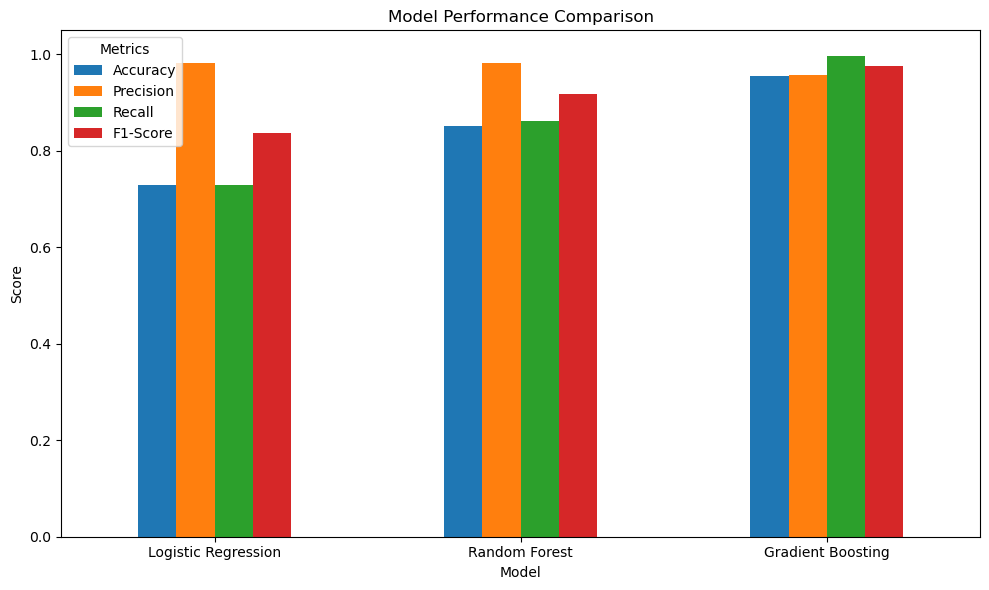

In [42]:
# Step 11: Model performance comparison graph

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

ax = model_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [43]:
# Step 12: Prediction score analysis

score_analysis = ranked_candidates["prediction_score"].describe()

print("Prediction Score Analysis")
print("-------------------------")
print(f"Minimum Score : {score_analysis['min']:.4f}")
print(f"Maximum Score : {score_analysis['max']:.4f}")
print(f"Mean Score    : {score_analysis['mean']:.4f}")
print(f"Median Score  : {score_analysis['50%']:.4f}")
print(f"Std. Deviation: {score_analysis['std']:.4f}")

# Count candidates in different score ranges
score_ranges = pd.cut(
    ranked_candidates["prediction_score"],
    bins=[0, 0.5, 0.7, 0.8, 0.9, 1.0],
    labels=[
        "0–0.50",
        "0.50–0.70",
        "0.70–0.80",
        "0.80–0.90",
        "0.90–1.00"
    ],
    include_lowest=True
)

score_distribution = score_ranges.value_counts().sort_index()

display(
    score_distribution.reset_index(
        name="Number of Problems"
    ).rename(
        columns={"prediction_score": "Prediction Score Range"}
    )
)

Prediction Score Analysis
-------------------------
Minimum Score : 0.1096
Maximum Score : 0.9982
Mean Score    : 0.9010
Median Score  : 0.9701
Std. Deviation: 0.1556


,Prediction Score Range,Number of Problems
0,0–0.50,396
1,0.50–0.70,554
2,0.70–0.80,449
3,0.80–0.90,904
4,0.90–1.00,6505


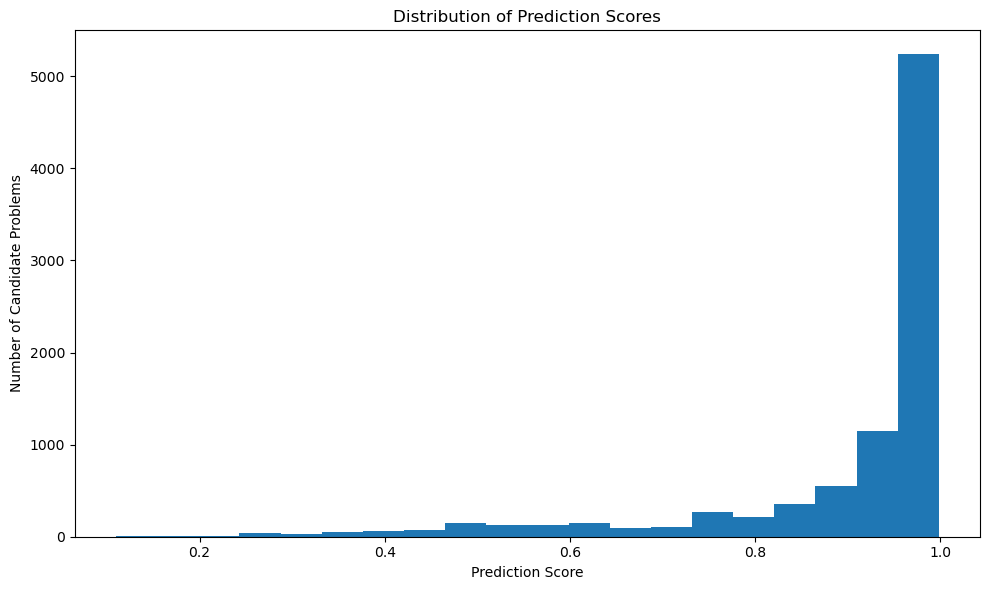

In [44]:
# Step 13: Prediction score distribution

plt.figure(figsize=(10, 6))

plt.hist(
    ranked_candidates["prediction_score"],
    bins=20
)

plt.title("Distribution of Prediction Scores")
plt.xlabel("Prediction Score")
plt.ylabel("Number of Candidate Problems")
plt.tight_layout()
plt.show()

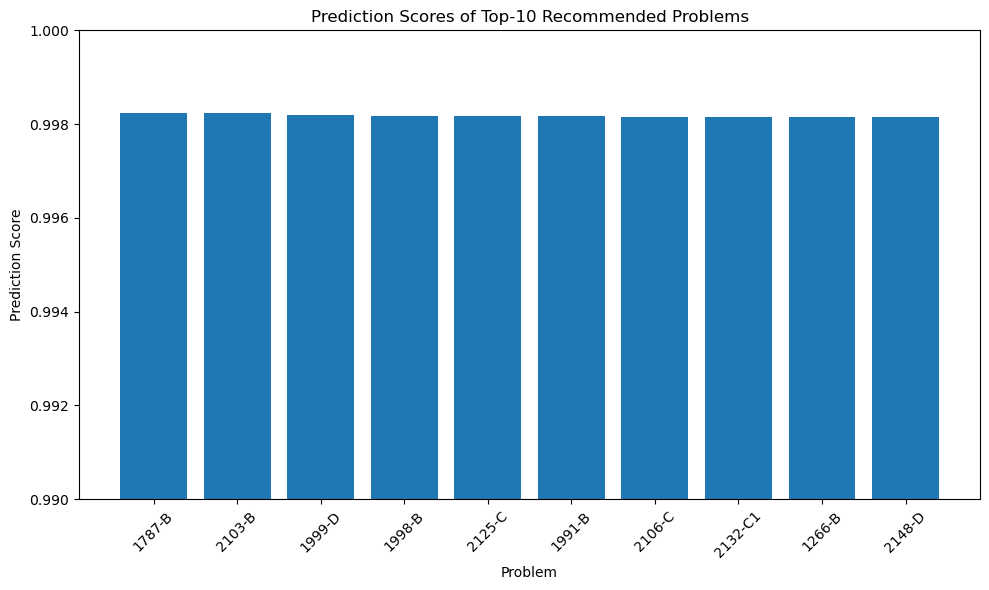

In [45]:
# Step 14: Top-10 recommendation score visualization

top_10 = ranked_candidates.head(10).copy()

plt.figure(figsize=(10, 6))

plt.bar(
    top_10["problem_id"].astype(str),
    top_10["prediction_score"]
)

plt.title("Prediction Scores of Top-10 Recommended Problems")
plt.xlabel("Problem")
plt.ylabel("Prediction Score")
plt.ylim(0.99, 1.00)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Feature,Importance
8,problem_solve_rate,0.523255
20,rating_skill_score,0.273769
4,user_avg_problem_rating,0.063368
12,topic_skill_score,0.033941
17,rating_performance_ratio,0.019338
15,rating_solve_rate,0.016592
0,user_solved_count,0.016398
2,user_solve_rate,0.011810
1,user_total_attempts,0.009931
19,rating_mastery,0.008865


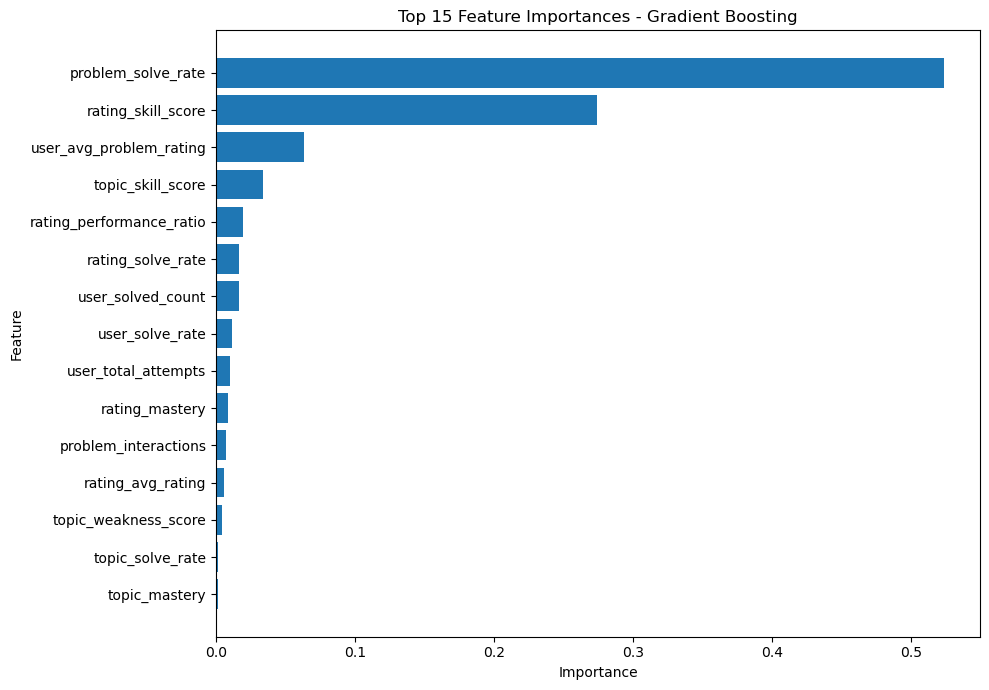

In [46]:
# Step 15: Gradient Boosting feature importance

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": gb_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
top_features = feature_importance.head(15)

display(top_features)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Feature Importances - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

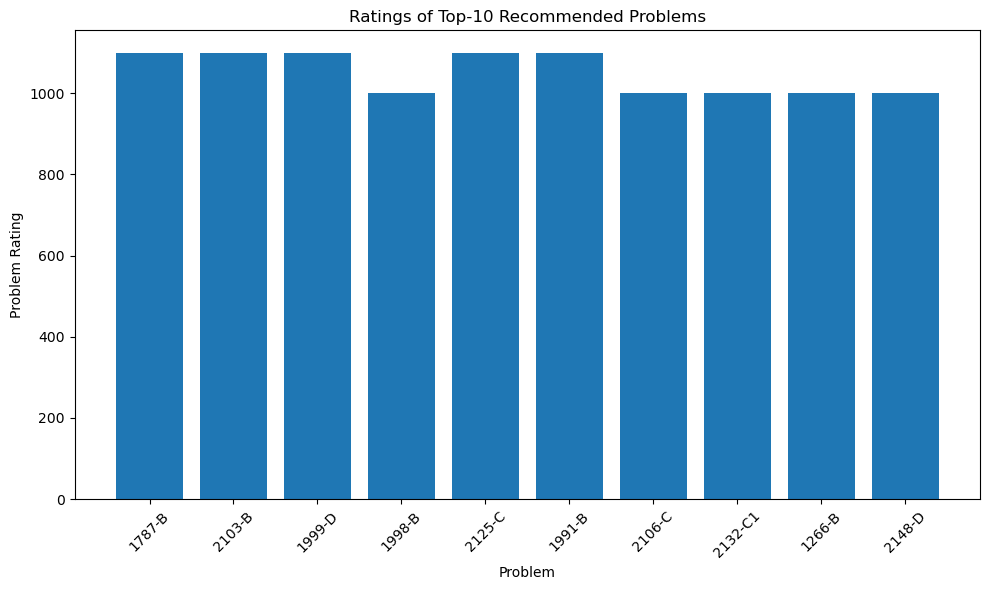

In [47]:
# Step 26: Rating distribution of Top-10 recommendations

top_10 = ranked_candidates.head(10).copy()

plt.figure(figsize=(10, 6))

plt.bar(
    top_10["problem_id"].astype(str),
    top_10["rating"]
)

plt.title("Ratings of Top-10 Recommended Problems")
plt.xlabel("Problem")
plt.ylabel("Problem Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Tag,Number of Recommendations
0,greedy,7
1,math,7
5,constructive algorithms,4
2,number theory,3
6,bitmasks,2
8,sortings,2
3,implementation,1
4,strings,1
7,combinatorics,1


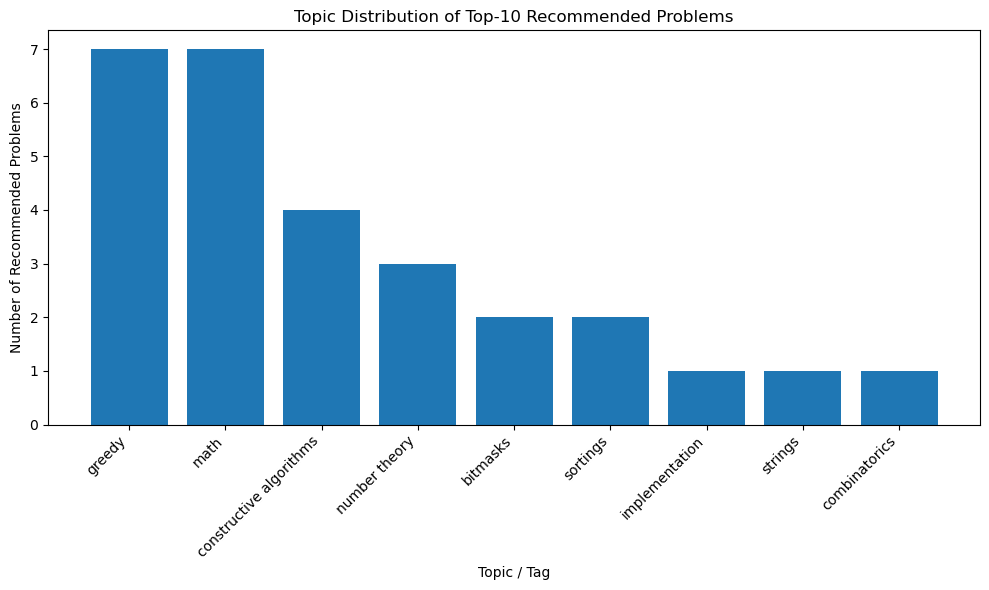

In [48]:
# Step 27: Analyze tags in the Top-10 recommendations

from collections import Counter

top_10 = ranked_candidates.head(10).copy()

# Extract all tags from the Top-10 problems
all_tags = []

for tags in top_10["tags"].dropna():
    all_tags.extend([tag.strip() for tag in str(tags).split(",")])

tag_counts = Counter(all_tags)

tag_analysis = pd.DataFrame(
    tag_counts.items(),
    columns=["Tag", "Number of Recommendations"]
).sort_values(
    by="Number of Recommendations",
    ascending=False
)

display(tag_analysis)

# Plot
plt.figure(figsize=(10, 6))

plt.bar(
    tag_analysis["Tag"],
    tag_analysis["Number of Recommendations"]
)

plt.title("Topic Distribution of Top-10 Recommended Problems")
plt.xlabel("Topic / Tag")
plt.ylabel("Number of Recommended Problems")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [49]:
# Model Comparison Results

print("=" * 65)
print("MODEL COMPARISON RESULTS")
print("=" * 65)

print(f"{'Model':<22} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1-Score':>10}")
print("-" * 65)

print(f"{'Logistic Regression':<22} "
      f"{0.7285:>10.4f} "
      f"{0.9818:>10.4f} "
      f"{0.7285:>10.4f} "
      f"{0.8364:>10.4f}")

print(f"{'Random Forest':<22} "
      f"{0.8523:>10.4f} "
      f"{0.9813:>10.4f} "
      f"{0.8614:>10.4f} "
      f"{0.9175:>10.4f}")

print(f"{'Gradient Boosting':<22} "
      f"{0.9550:>10.4f} "
      f"{0.9570:>10.4f} "
      f"{0.9976:>10.4f} "
      f"{0.9769:>10.4f}")

print("=" * 65)

MODEL COMPARISON RESULTS
Model                    Accuracy  Precision     Recall   F1-Score
-----------------------------------------------------------------
Logistic Regression        0.7285     0.9818     0.7285     0.8364
Random Forest              0.8523     0.9813     0.8614     0.9175
Gradient Boosting          0.9550     0.9570     0.9976     0.9769
